# Coordinated Wildfire Inspection with a Battery-Constrained Drone Fleet

**COMP6008 Reinforcement Learning — group project notebook**

| Section | Contributor(s) |
| --- | --- |
| 1–4 Setup, problem, MDP, environment | _(name)_ |
| 5–7 Baselines, feasibility mask, RL agents | _(name)_ |
| 8–13 Experiments, tuning, results, review | _(name)_ |

One central controller commands three drones that repeatedly inspect a changing fire field
and share one charger. We model the task as a fully observable finite-horizon MDP, implement
the environment as a Gymnasium environment, and compare three RL agents — **DQN**,
**REINFORCE with a learned baseline** and **synchronous A2C** — against conventional
controllers.

**Main finding.** With a feasibility mask (battery and collision rules applied to the action
choice), all three learners kept every drone alive in every final 40×40 mission, where the
unmasked learners and unrestricted random lost the fleet. The learned inspection quality,
however, stayed at the level of random feasible actions and far below the one-step Greedy
controller. Sections 8–12 document how we reached this result and why.

All code that runs in this notebook is defined in it. Training is opt-in (Section 1 flags);
by default the notebook reloads the archived results of the completed experiments.

## 1. Setup and reproduction

**Author: _(name)_**

Requirements: Python 3.11 or 3.12. From the repository root:

```bash
python -m pip install -r requirements.txt
python -m jupyter notebook Wildfire_Drone_Fleet_clean.ipynb
```

In Google Colab, clone the repository into `/content/wild-drone-appeared`, run
`%pip install -r requirements.txt`, and restart the kernel once.

**Data.** Archived results are read from the repository (no download needed):
`configs/` (environment and training settings), `docs/experiments/final-2026-10-05/`
(20×20 development study), `docs/experiments/rl-main-2026-10-11/` (frozen 40×40 study) and
`experiments/lithma/results/` (40×40 learning-rate sweep, sensitivity and planner runs).

**Flags.** With the defaults below, *Run All* takes a few minutes on a CPU and trains only
tiny demonstration models. Set `RUN_TRAINING = True` to retrain one frozen 40×40 fit
(about an hour on one CPU core), `RUN_SWEEP = True` to rerun the 40×40 learning-rate sweep
(nine fits), `RUN_MASK_COMPARISON = True` to retrain the 20×20 masked and unmasked agents
(eighteen fits), `RUN_PLANNER = True` to re-fly the baselines and the rolling-horizon planner
on the 20 final worlds (about 15 minutes), or `RUN_SENSITIVITY = True` to rerun the
sensitivity study (1,820 missions, over an hour). The sensitivity rerun includes the nine
trained main-study learners only if their weights have been downloaded as described in
`experiments/lithma/README.md`.

In [1]:
import copy, hashlib, json, random, sys, tempfile, time
from collections import deque
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from gymnasium import spaces
from IPython.display import display
from torch import nn
from torch.distributions import Categorical

RUN_TRAINING = False   # retrain one frozen 40×40 fit (slow)
RUN_SWEEP = False      # rerun the 40×40 learning-rate sweep (very slow)
RUN_MASK_COMPARISON = False  # retrain masked and unmasked agents at 20×20 (slow)
RUN_PLANNER = False    # re-fly the baselines and the planner on the 40×40 final worlds (slow)
RUN_SENSITIVITY = False  # rerun the 40×40 sensitivity study (very slow)

candidates = [Path.cwd(), Path.cwd().parent, Path('/content/wild-drone-appeared')]
REPO = next((p for p in candidates if (p/'configs/rl-main-frozen.json').exists()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook from the repository root (see setup above).')
HISTORICAL = REPO/'docs/experiments/final-2026-10-05'   # 20×20 development study
MAIN = REPO/'docs/experiments/rl-main-2026-10-11'       # frozen 40×40 main study
FOLLOW_UP = REPO/'experiments/lithma/results'           # 40×40 sweep, sensitivity, planner
FROZEN_CHECKPOINTS = REPO/'experiments/lithma/checkpoints'  # optional download of main-study weights
ALGORITHMS = ['dqn', 'reinforce', 'a2c']
POLICIES = ALGORITHMS + ['greedy', 'sweep', 'random', 'masked_random']
FROZEN_SOURCE = '855e5510ff46b16082ab7d551e7c228acab6f572'  # code revision of the main study

pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 5)
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})


def finish_plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)


print('Python', sys.version.split()[0], '| torch', torch.__version__, '| numpy', np.__version__)

Python 3.12.14 | torch 2.5.1 | numpy 2.4.6


## 2. Problem and why reinforcement learning

**Author: _(name)_**

One central controller commands three drones simultaneously. The task is persistent inspection of a synthetic changing fire field while sharing a single charger. The goal is recent inspection of important locations with low energy use, few blocked movements and no drone loss. Finishing a fit, retaining the fleet and performing useful surveillance are separate outcomes.

This is a **fully observable finite-horizon MDP**, not a partially observed field deployment. Terrain, fuel, fire, inspection ages, priority, all drone batteries and locations, wind, charger ownership and remaining time are available to the policy. Decisions trade immediate inspection against travel, battery reserve and charger contention. RL is investigated as a learned decision rule; strong planning baselines are essential because full state is available.

**Why it is hard.** The fleet decision is joint: 5 commands per drone give 125 joint actions
per step. Each drone must return before its battery empties, but the cost of flying too far
appears many steps later as a permanent loss. One charger creates contention, the fire
spreads stochastically, and missions last 160–300 steps.

**Why RL.** The task is a sequential decision problem under uncertainty with a clear
numeric objective, so an agent can in principle learn a policy that balances inspection,
travel and recharging from interaction alone. Because the full state is known, we also
compare against non-learning controllers that use the same information.

## 3. Markov decision process

**Author: _(name)_**

### State, observation and action

Let $S_t=(F_t,U_t,T,P,A_t,X_t,B_t,L_t,w_t,o_t,H-t)$. Here $F$ is burning status, $U$ fuel, $T$ terrain, $P$ static priority, $A$ inspection age, $X$ the three positions, $B$ batteries, $L$ loss flags, $w$ wind and $o\in\{-1,0,1,2\}$ the charger owner. Given $S_t$ and a joint action, the next-state distribution does not require earlier history. The complete random-generator state is used for reproducible simulation, not exposed as an observation.

| Observation | Raw state and normalization | Shape |
| --- | --- | --- |
| Map planes | burning, fuel/max fuel, terrain, priority/3, age/age limit | $5\times N\times N$ |
| Drone rows | row/(N−1), column/(N−1), battery/capacity, loss flag | $3\times4$ |
| Globals | wind one-hot (5), charger one-hot (4), base coordinates (2), remaining time (1) | 12 |
| Neural spatial augmentation | one location plane per live drone and one base plane | 4 additional maps |

Ages are capped at $\max(H,D+1)$, where $D$ is the inspection deadline. Three priority zones have priority 3, elsewhere 1. Terrain and initial fuel/fire/priority placement vary by scenario seed; all drones start at the central base with full batteries. Fuel at base is zero. These dimensionless settings are a simplified cellular model, not calibrated fire physics or aircraft endurance.

Each drone command is stay/up/down/left/right, indexed 0–4. The joint action is
$$a=25c_0+5c_1+c_2\in\{0,\ldots,124\}.$$
This is one simultaneous fleet decision, not three environment steps.

### Transition model and reward

The implemented step order matters:

1. Decode the action; resolve off-grid proposals and iterative same-cell/swap conflicts. Multiple drones may occupy base. Off-grid proposals revert; the collision count records blocked moving drones in conflicts, not all invalid commands.
2. Apply charging, energy use and new losses. Charging requires a live drone to have been at base and to stay there. Arrivals cannot charge on the arrival step. A retained eligible owner charges; otherwise lowest battery then drone ID chooses an owner. A full charge releases ownership.
3. Increase inspection ages with the cap. Compute hazard-weighted priorities using the fire **before** its evolution. Inspect the union of live drones' square footprints, clipped at boundaries, and reset those ages to zero. Overlap is counted once per step; grounded drones also inspect.
4. Compute reward and inspection metrics, then evolve fire/wind and advance time. The returned observation contains the evolved fire; reported inspection freshness/overdue retain the pre-fire evaluation weights.
5. End at $H$ or when all drones are lost. The environment reports this as termination, with remaining time included in state; it does not report an external truncation.

For $W_t(x)=P(x)(1+2F_t(x)+\mathbf1_{\mathrm{frontier}}(x))$, aged values $A_t^+(x)$ and inspection union $I_t$,
$$g_t=\frac{\sum_{x\in I_t}W_t(x)\min(A_t^+(x)/D,1)}{\sum_x W_t(x)}.$$
With post-inspection ages $\widetilde A_t$, freshness and overdue are
$$f_t=\frac{\sum_x W_t(x)[1-\min(\widetilde A_t(x)/D,1)]}{\sum_xW_t(x)},\qquad
u_t=\frac{\sum_x W_t(x)\mathbf1[\widetilde A_t(x)>D]}{\sum_xW_t(x)}.$$
The reward uses **inspection gain**, not the full freshness score:
$$r_t=\alpha g_t-\beta u_t-\lambda E_t/B_{\max}-\kappa C_t-\mu\Delta L_t
-\beta(H-t-1)\mathbf1[\text{all lost after this action}].$$
Main-study weights are $(\alpha,\beta,\lambda,\kappa,\mu)=(1,0.1,0.02,0.2,5)$. $E_t$ is actual energy spent, $C_t$ counts blocked movers and $\Delta L_t$ is newly lost drones. Commanded non-stay moves still cost move energy when blocked; a ground stay costs zero, an airborne stay costs hover energy. Batteries empty away from base cause permanent loss.

Each burning orthogonal neighbour contributes clipped ignition probability $p_j=\mathrm{clip}(p_0\,T(x)\,b_j,0,1)$, with wind multiplier $b_j$ in the wind direction. Ignition probability is $1-\prod_j(1-p_j)$. Existing burning cells consume one unit of fuel; newly ignited cells start consuming on the next step. A wind change redraw may choose the existing wind. Random samples are drawn every step independently of drone actions, enabling paired-world comparisons.

Metrics use the full planned horizon: after early fleet failure, remaining freshness is zero and overdue is one. Safe returns and charge completions are event counts, not “all drones finished at base.” Inspection visits are not unique land coverage. A freshness value of 0.08 is not 8% of land covered.

## 4. Environment implementation

**Author: _(name)_**

The environment follows the
`gymnasium.Env` interface. The cells below are the implementation used for every experiment;
comments refer to the transition steps 1–5 of Section 3.

In [2]:
# Simulator settings (dimensionless, illustrative values)
@dataclass(frozen=True)
class EnvConfig:
    grid_size: int = 40
    horizon: int = 300
    battery_capacity: float = 160.0
    move_cost: float = 1.0
    hover_cost: float = 0.25
    recharge_rate: float = 8.0
    sensor_radius: int = 2
    inspection_deadline: int = 30
    max_fuel: int = 180
    initial_fires: int = 3
    spread_probability: float = 0.04
    wind_multiplier: float = 2.0
    wind_change_probability: float = 0.06
    freshness_reward: float = 1.0
    overdue_penalty: float = 0.1
    energy_penalty: float = 0.02
    collision_penalty: float = 0.2
    loss_penalty: float = 5.0

    def __post_init__(self):
        for name in ('grid_size', 'horizon', 'inspection_deadline', 'max_fuel', 'initial_fires'):
            value = getattr(self, name)
            if not isinstance(value, int) or isinstance(value, bool) or value < 1:
                raise ValueError(f'{name} must be a positive integer')
        if self.grid_size < 4:
            raise ValueError('grid_size must be at least 4')
        if not isinstance(self.sensor_radius, int) or self.sensor_radius < 0:
            raise ValueError('sensor_radius must be a nonnegative integer')
        if self.initial_fires > self.grid_size**2 - 1:
            raise ValueError('too many initial fires')
        for name in ('battery_capacity', 'move_cost', 'hover_cost', 'recharge_rate'):
            if not 0 < getattr(self, name) < float('inf'):
                raise ValueError(f'{name} must be finite and positive')
        for name in ('spread_probability', 'wind_change_probability'):
            if not 0 <= getattr(self, name) <= 1:
                raise ValueError(f'{name} must be in [0, 1]')
        if not 1 <= self.wind_multiplier < float('inf'):
            raise ValueError('wind_multiplier must be finite and at least 1')
        for name in ('freshness_reward', 'overdue_penalty', 'energy_penalty',
                     'collision_penalty', 'loss_penalty'):
            if not 0 <= getattr(self, name) < float('inf'):
                raise ValueError(f'{name} must be finite and nonnegative')

    def to_dict(self):
        return asdict(self)

In [3]:
MOVES = np.array([[0, 0], [-1, 0], [1, 0], [0, -1], [0, 1]], dtype=np.int32)


WIND = np.array([[0, 0], [-1, 0], [1, 0], [0, -1], [0, 1]], dtype=np.int32)


def decode_action(action: int) -> np.ndarray:
    if not isinstance(action, (int, np.integer)) or not 0 <= action < 125:
        raise ValueError('joint action must be an integer in [0, 124]')
    return np.array([action // 25, (action // 5) % 5, action % 5], dtype=np.int32)


def encode_action(commands) -> int:
    commands = np.asarray(commands)
    if commands.shape != (3,) or not np.issubdtype(commands.dtype, np.integer):
        raise ValueError('expected three integer commands')
    if np.any((commands < 0) | (commands > 4)):
        raise ValueError('each command must be in [0, 4]')
    return int(commands @ np.array([25, 5, 1]))


def neighbour_count(grid: np.ndarray) -> np.ndarray:
    out = np.zeros_like(grid, dtype=np.float32)
    out[1:] += grid[:-1]
    out[:-1] += grid[1:]
    out[:, 1:] += grid[:, :-1]
    out[:, :-1] += grid[:, 1:]
    return out


class WildfireFleetEnv(gym.Env):
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 8}

    def __init__(self, config: EnvConfig | None = None, render_mode: str | None = None):
        self.config = config or EnvConfig()
        if render_mode not in (None, 'rgb_array'):
            raise ValueError('supported render mode: rgb_array')
        self.render_mode = render_mode
        n = self.config.grid_size
        self.age_limit = max(self.config.horizon, self.config.inspection_deadline+1)
        self.action_space = spaces.Discrete(125)
        self.observation_space = spaces.Dict({
            'maps': spaces.Box(0, 1, shape=(5, n, n), dtype=np.float32),
            'drones': spaces.Box(0, 1, shape=(3, 4), dtype=np.float32),
            'globals': spaces.Box(0, 1, shape=(12,), dtype=np.float32),
        })
        self._done = True

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        c, rng = self.config, self.np_random
        n = c.grid_size
        self.base = np.array([n // 2, n // 2], dtype=np.int32)
        self.terrain = rng.uniform(0.4, 1, (n, n)).astype(np.float32)
        self.fuel = rng.integers(max(1, c.max_fuel // 2), c.max_fuel + 1, (n, n))
        self.fuel[tuple(self.base)] = 0
        self.priority = np.ones((n, n), dtype=np.float32)
        # Three high-priority zones differ in each complete scenario.
        radius = max(1, n // 8)
        for r, col in rng.integers(0, n, size=(3, 2)):
            self.priority[max(0, r-radius):min(n, r+radius+1),
                          max(0, col-radius):min(n, col+radius+1)] = 3
        self.burning = np.zeros((n, n), dtype=bool)
        available = np.flatnonzero(self.fuel)
        self.burning.flat[rng.choice(available, c.initial_fires, replace=False)] = True
        self.ages = np.full((n, n), c.inspection_deadline, dtype=np.int32)
        self.positions = np.tile(self.base, (3, 1))
        self.batteries = np.full(3, c.battery_capacity, dtype=np.float32)
        self.lost = np.zeros(3, dtype=bool)
        self.wind = int(rng.integers(0, 5))
        self.charger_owner = -1
        self.elapsed = 0
        self.totals = dict(energy_used=0.0, collision_attempts=0, safe_returns=0,
                           charge_completions=0, inspected_cells=0, episode_return=0.0)
        self._done = False
        return self._observation(), self._info()

    def _observation(self):
        c = self.config
        maps = np.stack([self.burning, self.fuel/c.max_fuel, self.terrain,
                         self.priority/3, self.ages/self.age_limit]).astype(np.float32)
        drones = np.column_stack([self.positions/(c.grid_size-1),
                                  self.batteries/c.battery_capacity, self.lost])
        globals_ = np.concatenate([
            np.eye(5)[self.wind], np.eye(4)[self.charger_owner+1],
            self.base/(c.grid_size-1), [1-self.elapsed/c.horizon],
        ])
        return {'maps': maps, 'drones': drones.astype(np.float32),
                'globals': globals_.astype(np.float32)}

    def priority_weights(self):
        frontier = (neighbour_count(self.burning) > 0) & (self.fuel > 0) & ~self.burning
        return self.priority * (1 + 2*self.burning + frontier)

    def _metrics(self, weights=None):
        weights = self.priority_weights() if weights is None else weights
        denominator = float(weights.sum())
        freshness = 1-np.minimum(self.ages/self.config.inspection_deadline, 1)
        return {'weighted_freshness': float((weights*freshness).sum()/denominator),
                'overdue_fraction': float((weights*(self.ages >
                                                   self.config.inspection_deadline)).sum()
                                          / denominator),
                'burning_cells': int(self.burning.sum()),
                'total_losses': int(self.lost.sum())}

    def _info(self, **extra):
        return {'step': self.elapsed, **self._metrics(), **self.totals, **extra}

    def _resolve_moves(self, commands):
        proposed = self.positions + MOVES[commands]
        proposed[self.lost] = self.positions[self.lost]
        invalid = np.any((proposed < 0) | (proposed >= self.config.grid_size), axis=1)
        proposed[invalid] = self.positions[invalid]
        blocked = np.zeros(3, dtype=bool)
        while True:
            reject = np.zeros(3, dtype=bool)
            for i in range(3):
                for j in range(i+1, 3):
                    if self.lost[i] or self.lost[j]:
                        continue
                    same = np.array_equal(proposed[i], proposed[j])
                    at_base = np.array_equal(proposed[i], self.base)
                    swap = (np.array_equal(proposed[i], self.positions[j]) and
                            np.array_equal(proposed[j], self.positions[i]) and
                            not np.array_equal(self.positions[i], self.positions[j]))
                    if (same and not at_base) or swap:
                        for k in (i, j):
                            if not np.array_equal(proposed[k], self.positions[k]):
                                reject[k] = True
            if not reject.any():
                break
            blocked |= reject
            proposed[reject] = self.positions[reject]
        self.positions = proposed
        return int(blocked.sum())

    def _energy_and_charging(self, commands, previous):
        c = self.config
        at_base = np.all(self.positions == self.base, axis=1)
        was_at_base = np.all(previous == self.base, axis=1)
        ground_stay = at_base & was_at_base & (commands == 0) & ~self.lost
        eligible = ground_stay & (self.batteries < c.battery_capacity)
        owner = self.charger_owner
        if owner < 0 or not eligible[owner]:
            ids = np.flatnonzero(eligible)
            owner = min(ids, key=lambda i: (self.batteries[i], i)) if len(ids) else -1
        completions = 0
        if owner >= 0:
            self.batteries[owner] = min(c.battery_capacity,
                                         self.batteries[owner] + c.recharge_rate)
            completions = int(self.batteries[owner] == c.battery_capacity)
        self.charger_owner = int(owner) if not completions else -1
        costs = np.where(commands == 0, c.hover_cost, c.move_cost)
        costs[ground_stay | self.lost] = 0
        spent = np.minimum(self.batteries, costs)
        self.batteries[:] = np.maximum(self.batteries - costs, 0)
        newly_lost = ~self.lost & ~at_base & (self.batteries <= 0)
        self.lost |= newly_lost
        returns = int(np.count_nonzero(at_base & ~was_at_base & ~self.lost))
        return float(spent.sum()), int(newly_lost.sum()), returns, completions

    def _inspection_mask(self):
        n, radius = self.config.grid_size, self.config.sensor_radius
        mask = np.zeros((n, n), dtype=bool)
        for (r, col), lost in zip(self.positions, self.lost, strict=True):
            if not lost:
                mask[max(0, r-radius):min(n, r+radius+1),
                     max(0, col-radius):min(n, col+radius+1)] = True
        return mask

    def _evolve_fire(self):
        c, n = self.config, self.config.grid_size
        # All random samples are drawn every step, independent of fleet actions.
        draws = self.np_random.random((n, n))
        change_draw = self.np_random.random()
        new_wind = int(self.np_random.integers(0, 5))
        survival = np.ones((n, n), dtype=np.float64)
        for dr, dc in MOVES[1:]:
            neighbours = np.zeros((n, n), dtype=bool)
            r0, r1 = max(0, dr), n+min(0, dr)
            c0, c1 = max(0, dc), n+min(0, dc)
            neighbours[r0:r1, c0:c1] = self.burning[r0-dr:r1-dr, c0-dc:c1-dc]
            boost = c.wind_multiplier if np.array_equal([dr, dc], WIND[self.wind]) else 1
            probability = np.clip(c.spread_probability*boost*self.terrain, 0, 1)
            survival *= np.where(neighbours, 1-probability, 1)
        ignite = ~self.burning & (self.fuel > 0) & (draws < 1-survival)
        self.fuel[self.burning] = np.maximum(self.fuel[self.burning]-1, 0)
        self.burning = (self.burning & (self.fuel > 0)) | ignite
        if change_draw < c.wind_change_probability:
            self.wind = new_wind

    def step(self, action):
        if self._done:
            raise RuntimeError('call reset() before stepping a finished environment')
        commands = decode_action(action)
        previous = self.positions.copy()
        collisions = self._resolve_moves(commands)
        energy, losses, returns, completions = self._energy_and_charging(commands, previous)
        self.ages[:] = np.minimum(self.ages+1, self.age_limit)
        weights = self.priority_weights()
        mask = self._inspection_mask()
        gain = float((weights[mask]*np.minimum(
            self.ages[mask]/self.config.inspection_deadline, 1)).sum()/weights.sum())
        self.ages[mask] = 0
        inspection_metrics = self._metrics(weights)
        c = self.config
        components = {
            'freshness_gain': c.freshness_reward*gain,
            'overdue': -c.overdue_penalty*inspection_metrics['overdue_fraction'],
            'energy': -c.energy_penalty*energy/c.battery_capacity,
            'collisions': -c.collision_penalty*collisions,
            'losses': -c.loss_penalty*losses,
            'mission_failure': (-c.overdue_penalty*(c.horizon-self.elapsed-1)
                                if self.lost.all() else 0.0),
        }
        reward = float(sum(components.values()))
        self._evolve_fire()
        self.elapsed += 1
        self._done = bool(self.lost.all() or self.elapsed >= c.horizon)
        for key, value in dict(energy_used=energy, collision_attempts=collisions,
                               safe_returns=returns, charge_completions=completions,
                               inspected_cells=int(mask.sum()), episode_return=reward).items():
            self.totals[key] += value
        info = self._info(**inspection_metrics, reward_components=components,
                          new_losses=losses, inspected_cells=int(mask.sum()),
                          safe_returns=returns, charge_completions=completions,
                          collision_attempts=collisions, energy_used=energy,
                          totals=self.totals.copy())
        return self._observation(), reward, self._done, False, info

In [4]:
from gymnasium.utils.env_checker import check_env

frozen = json.loads((REPO/'configs/rl-main-frozen.json').read_text())
development = json.loads((REPO/'configs/development.json').read_text())
main_env = EnvConfig(**frozen['environment'])
check_env(WildfireFleetEnv(main_env), skip_render_check=True)
assert all(encode_action(decode_action(a)) == a for a in range(125))
print('Gymnasium environment check and all 125 action encodings passed.')

Gymnasium environment check and all 125 action encodings passed.


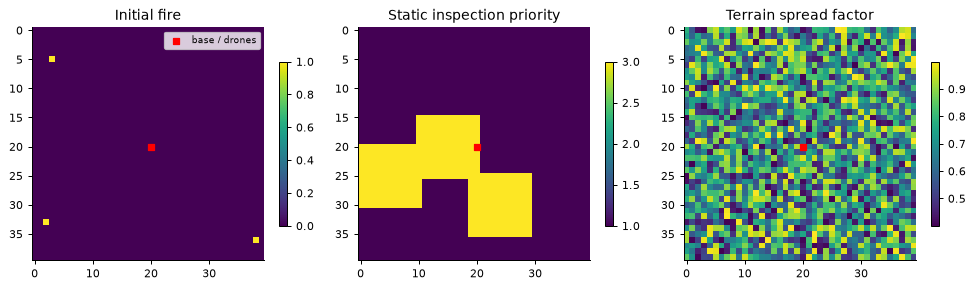

In [5]:
env = WildfireFleetEnv(main_env)
env.reset(seed=0)  # existing training world; illustration only
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, data, title in zip(axes, [env.burning, env.priority, env.terrain],
                         ['Initial fire', 'Static inspection priority', 'Terrain spread factor']):
    im = ax.imshow(data, origin='upper', cmap='viridis')
    ax.scatter([env.base[1]], [env.base[0]], marker='s', color='red', s=25, label='base / drones')
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.7)
axes[0].legend(fontsize=7)
finish_plot(fig)

## 5. Baselines and the feasibility mask

**Author: _(name)_**

| Controller | Decision rule | Role |
| --- | --- | --- |
| Random | Uniform over all 125 commands | Unrestricted reference |
| Masked random | Uniform over feasible joint commands | Isolates the contribution of feasibility rules |
| Greedy | Scores native candidate actions by immediate inspection value | Strong surveillance baseline |
| Sweep | Follows a systematic route with battery-aware native candidates | Structured nonlearned patrol |
| All stay | Keeps every drone at base | Historical trivial safe control |
| Rolling-horizon planner | Short lookahead over candidates and sampled transitions | Historical 20×20 planning reference |

The frozen 40×40 comparison uses the first four; the rolling-horizon planner was evaluated on the same worlds in a separate follow-up (Section 10).

The learned mask first uses `candidate_actions`, which checks movement, collisions and battery reserve. If the only feasible proposal is all stay while an away drone has low battery, `emergency_return_mask` prioritizes collision-free baseward movement by battery margin. The mask is a deterministic state-dependent restriction on the policy, not a learned module or a formal safety proof. Greedy and sweep retain their own native preferences; do not claim all controllers have identical proposal rules.

Infeasible actor logits become the lowest finite representable value, producing zero probability and finite entropy. DQN excludes infeasible actions both from action choice and the next-state target. Masked random uses exactly the learners' mask. Final learned evaluation uses deterministic first-index argmax for Q values or actor logits; stochastic actor sampling during training is not the evaluation rule.

**Why a mask?** The learners originally had no battery rule. In the 20×20 development
study (Section 8) the unmasked DQN, REINFORCE and A2C lost 1.7–3 drones per mission, while
every conventional controller kept its fleet because `candidate_actions` filters out moves
that would strand a drone. The mask gives the learners the same feasibility rule, so the
comparison measures inspection decisions rather than who was told about batteries. The idea
follows *shielding* in safe RL (Alshiekh et al., 2018).

In [6]:
COMMANDS = np.stack([decode_action(a) for a in range(125)])


def candidate_actions(env):
    """Feasible baseline proposals. This is NOT a shield applied to RL policies."""
    c = env.config
    proposed = env.positions[None, :, :] + MOVES[COMMANDS]
    valid = ~np.any((proposed < 0) | (proposed >= c.grid_size), axis=(1, 2))
    distances = np.abs(proposed-env.base).sum(axis=2)
    current_distances = np.abs(env.positions-env.base).sum(axis=1)
    for i in range(3):
        if env.lost[i]:
            valid &= COMMANDS[:, i] == 0
            continue
        if current_distances[i] == 0 and env.batteries[i] < c.battery_capacity:
            valid &= COMMANDS[:, i] == 0
            continue
        costs = np.where(COMMANDS[:, i] == 0, c.hover_cost, c.move_cost)
        if current_distances[i] == 0:
            costs[COMMANDS[:, i] == 0] = 0
        low_battery = env.batteries[i] <= current_distances[i]*c.move_cost + 3*c.move_cost
        if low_battery and current_distances[i] > 0:
            valid &= distances[:, i] < current_distances[i]
        else:
            valid &= ((env.batteries[i]-costs >= distances[:, i]*c.move_cost+c.move_cost)
                      | (distances[:, i] == 0))
    for i in range(3):
        for j in range(i+1, 3):
            if env.lost[i] or env.lost[j]:
                continue
            same = np.all(proposed[:, i] == proposed[:, j], axis=1)
            base = np.all(proposed[:, i] == env.base, axis=1)
            swap = (np.all(proposed[:, i] == env.positions[j], axis=1) &
                    np.all(proposed[:, j] == env.positions[i], axis=1))
            if np.array_equal(env.positions[i], env.positions[j]):
                swap[:] = False
            valid &= ~(same & ~base) & ~swap
    indices = np.flatnonzero(valid)
    # If resource/collision constraints make every heuristic proposal impossible,
    # do not silently teleport or restore battery; the environment still decides.
    if not len(indices):
        indices = np.array([0])
    return indices, proposed[indices]


class RandomPolicy:
    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)

    def act(self, env, observation):
        return int(self.rng.integers(125))


class GreedyPolicy:
    def act(self, env, observation):
        ids, positions = candidate_actions(env)
        r, col = np.indices((env.config.grid_size, env.config.grid_size))
        covered = ((np.abs(r[None, None]-positions[:, :, 0, None, None]) <=
                    env.config.sensor_radius) &
                   (np.abs(col[None, None]-positions[:, :, 1, None, None]) <=
                    env.config.sensor_radius) & ~env.lost[None, :, None, None]).any(axis=1)
        urgency = env.priority_weights()*np.minimum(
            (env.ages+1)/env.config.inspection_deadline, 1)
        score = (covered*urgency).sum(axis=(1, 2))
        # Equal-information candidates favour less movement; no future reward estimate.
        score -= np.count_nonzero(COMMANDS[ids], axis=1)*0.001
        return int(ids[np.argmax(score)])


class SweepPolicy:
    def __init__(self):
        self.waypoints = None
        self.cursors = np.zeros(3, dtype=int)

    def _initialise(self, env):
        n, radius = env.config.grid_size, env.config.sensor_radius
        self.waypoints = []
        for i, columns in enumerate(np.array_split(np.arange(n), 3)):
            points = []
            rows = list(range(min(radius, n-1), n, max(1, 2*radius+1)))
            if rows[-1] != n-1:
                rows.append(n-1)
            for k, row in enumerate(rows):
                ends = [int(columns[0]), int(columns[-1])]
                if k % 2:
                    ends.reverse()
                points.extend((row, col) for col in ends)
            self.waypoints.append(np.array(points))
            self.cursors[i] = 0

    def act(self, env, observation):
        if self.waypoints is None or env.elapsed == 0:
            self._initialise(env)
        targets = []
        for i in range(3):
            points = self.waypoints[i]
            target = points[self.cursors[i]]
            if np.array_equal(env.positions[i], target):
                self.cursors[i] = (self.cursors[i]+1) % len(points)
                target = points[self.cursors[i]]
            distance = int(np.abs(env.positions[i]-env.base).sum())
            if env.batteries[i] <= distance*env.config.move_cost+3*env.config.move_cost:
                target = env.base
            targets.append(target)
        ids, proposed = candidate_actions(env)
        score = -np.abs(proposed-np.array(targets)[None]).sum(axis=(1, 2))
        return int(ids[np.argmax(score)])


class RollingHorizonPolicy:
    """Bounded stochastic shooting planner; independent hypothetical futures."""

    def __init__(self, seed=0, horizon=4, candidates=8, samples=2, gamma=0.99):
        if min(horizon, candidates, samples) < 1:
            raise ValueError('planner horizon, candidates and samples must be positive')
        self.rng = np.random.default_rng(seed)
        self.horizon, self.candidates, self.samples, self.gamma = (
            horizon, candidates, samples, gamma)
        self.greedy = GreedyPolicy()

    def act(self, env, observation):
        valid, _ = candidate_actions(env)
        first = [self.greedy.act(env, observation)]
        first.extend(int(a) for a in self.rng.choice(valid, self.candidates-1))
        future_seeds = self.rng.integers(0, 2**31, self.samples)
        proposal_seeds = self.rng.integers(0, 2**31, len(first))
        scores = []
        for action, proposal_seed in zip(first, proposal_seeds, strict=True):
            returns = []
            for future_seed in future_seeds:
                model = copy.deepcopy(env)
                # Do not use the cloned real RNG state to predict what happens next.
                model.np_random = np.random.default_rng(int(future_seed))
                proposal_rng = np.random.default_rng(int(proposal_seed))
                total, command = 0.0, action
                for t in range(self.horizon):
                    obs, reward, done, _, _ = model.step(command)
                    total += self.gamma**t*reward
                    if done:
                        break
                    if proposal_rng.random() < 0.75:
                        command = self.greedy.act(model, obs)
                    else:
                        choices, _ = candidate_actions(model)
                        command = int(proposal_rng.choice(choices))
                total += 0.1*model._metrics()['weighted_freshness']
                returns.append(total)
            scores.append(np.mean(returns))
        return first[int(np.argmax(scores))]

In [7]:
def action_mask(env):
    """Boolean (125,) mask of joint actions the baselines' proposal rule allows.

    The rule checks battery and collisions jointly. When low-battery drones' only base-ward
    cells collide, no joint action passes and it falls back to all-stay, so the drones hover
    until a battery empties (observed with a learned policy). In that case only, use
    `emergency_return_mask` instead.
    """
    mask = np.zeros(125, dtype=bool)
    mask[candidate_actions(env)[0]] = True
    away = ~env.lost & np.any(env.positions != env.base, axis=1)
    distances = np.abs(env.positions-env.base).sum(axis=1)
    low = away & (env.batteries <= (distances+3)*env.config.move_cost)
    if mask.sum() == 1 and mask[0] and low.any():
        return emergency_return_mask(env)
    return mask


def emergency_return_mask(env):
    """Collision-free return: each away drone moves closer to base or waits.

    A blocked move still costs a full move, so conflicting proposals are excluded. Drones
    with the smallest battery margin (battery minus distance) get priority to move; only
    the joint actions with the best priority-weighted number of moving drones remain.
    """
    positions, base = env.positions, env.base
    away = ~env.lost & np.any(positions != base, axis=1)
    distances = np.abs(positions-base).sum(axis=1)
    proposed = positions[None] + MOVES[COMMANDS]
    closer = np.abs(proposed-base).sum(axis=2) < distances
    feasible = np.all(np.where(away, closer | (COMMANDS == 0), COMMANDS == 0), axis=1)
    for i in range(3):
        for j in range(i+1, 3):
            if env.lost[i] or env.lost[j]:
                continue
            same = np.all(proposed[:, i] == proposed[:, j], axis=1)
            at_base = np.all(proposed[:, i] == base, axis=1)
            swap = (np.all(proposed[:, i] == positions[j], axis=1) &
                    np.all(proposed[:, j] == positions[i], axis=1))
            feasible &= ~(same & ~at_base) & ~swap
    margin = np.where(away, env.batteries-distances*env.config.move_cost, np.inf)
    priority = np.zeros(3)
    priority[np.argsort(margin, kind='stable')] = [4, 2, 1]  # critical drone outranks others
    score = ((COMMANDS != 0) & away) @ priority
    score[~feasible] = -1
    return score == score.max()


def apply_mask(logits, mask):
    """Give infeasible actions the lowest finite logit: zero probability, finite entropy."""
    mask = torch.as_tensor(mask, device=logits.device).reshape(logits.shape)
    return logits.masked_fill(~mask, torch.finfo(logits.dtype).min)


def masked_max(q_values, masks):
    """Maximum Q over feasible next actions only (DQN target)."""
    return apply_mask(q_values, masks).max(dim=1).values


class MaskedRandomPolicy:
    """Uniform over feasible joint actions: the reference a masked learner must beat."""

    def __init__(self, seed=0):
        self.rng = np.random.default_rng(seed)

    def act(self, env, observation):
        return int(self.rng.choice(np.flatnonzero(action_mask(env))))

In [8]:
env = WildfireFleetEnv(main_env)
env.reset(seed=0)
mask = action_mask(env)
print('Feasible joint actions at reset:', int(mask.sum()), 'of 125')

# The rule's deadlock case: three low-battery drones whose only base-ward cells collide.
deadlock = WildfireFleetEnv(EnvConfig(**development['environment']))
deadlock.reset(seed=5000)
deadlock.positions = np.array([[9, 9], [8, 10], [10, 8]], dtype=np.int32)
deadlock.batteries = np.array([3.5, 2.0, 3.5], dtype=np.float32)
print('candidate_actions alone:', candidate_actions(deadlock)[0].tolist(), '(all stay → hover until empty)')
print('mask with emergency return:', [decode_action(int(a)).tolist()
                                      for a in np.flatnonzero(action_mask(deadlock))])

Feasible joint actions at reset: 73 of 125
candidate_actions alone: [0] (all stay → hover until empty)
mask with emergency return: [[2, 2, 0]]


## 6. Reinforcement learning agents

**Author: _(name)_**

### Shared network and training conventions

The neural input is nine map channels plus a 24-value vector. Two $3\times3$ convolutions (16 then 32 channels, stride 2, padding 1) feed a flattened map representation concatenated with the vector. A 128-unit ReLU encoder feeds 125 joint scores. REINFORCE with a learned baseline and A2C also have a scalar value head. The grid size changes the flattened dimension; no 20×20 checkpoint transfer into 40×40 is claimed.

Each fit seeds Python, NumPy, PyTorch and the independent sampler, uses one PyTorch CPU thread and deterministic algorithms, initializes from scratch and uses Adam. Gradients are clipped at norm 0.5. Main-study shaping weight is zero. The three training seeds vary initialization and stochastic decisions; they share the declared training scenario sequence. Evaluation uses final checkpoints only.

The code cells below are the implementation. Comments in the training loop carry the pseudocode step labels (D1–D8, R1–R7, A1–A6) so each step can be traced.

In [9]:
@dataclass(frozen=True)
class TrainConfig:
    episodes: int = 20
    seed: int = 0
    scenario_seed_start: int = 0
    learning_rate: float = 0.0003
    gamma: float = 0.99
    batch_size: int = 32
    replay_size: int = 2000
    warmup_steps: int = 128
    target_update_steps: int = 100
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 10000
    n_steps: int = 16
    entropy_weight: float = 0.01
    value_weight: float = 0.5
    max_grad_norm: float = 0.5
    device: str = 'cpu'
    spatial_encoding: bool = True
    monte_carlo_baseline: bool = True
    double_dqn: bool = False
    coordination_shaping_weight: float = 0.0
    checkpoint_interval: int = 25
    progress_interval: int = 10
    validation_interval: int = 25
    validation_seeds: tuple[int, ...] = ()

    def __post_init__(self):
        for name in ('episodes', 'batch_size', 'replay_size', 'warmup_steps',
                     'target_update_steps', 'epsilon_decay_steps', 'n_steps'):
            if not isinstance(getattr(self, name), int) or getattr(self, name) < 1:
                raise ValueError(f'{name} must be a positive integer')
        if self.replay_size < self.batch_size:
            raise ValueError('replay_size must be at least batch_size')
        if not 0 <= self.gamma <= 1:
            raise ValueError('gamma must be in [0, 1]')
        if not 0 <= self.epsilon_end <= self.epsilon_start <= 1:
            raise ValueError('require 0 <= epsilon_end <= epsilon_start <= 1')
        for name in ('learning_rate', 'max_grad_norm'):
            if not 0 < getattr(self, name) < float('inf'):
                raise ValueError(f'{name} must be finite and positive')
        for name in ('entropy_weight', 'value_weight'):
            if not 0 <= getattr(self, name) < float('inf'):
                raise ValueError(f'{name} must be finite and nonnegative')
        if (isinstance(self.coordination_shaping_weight, bool) or
                not 0 <= self.coordination_shaping_weight < float('inf')):
            raise ValueError('coordination_shaping_weight must be finite and nonnegative')
        if self.seed < 0 or self.scenario_seed_start < 0:
            raise ValueError('seeds must be nonnegative')
        if self.device not in ('cpu', 'cuda', 'auto'):
            raise ValueError('device must be cpu, cuda or auto')
        for name in ('checkpoint_interval', 'validation_interval'):
            if not isinstance(getattr(self, name), int) or getattr(self, name) < 1:
                raise ValueError(f'{name} must be a positive integer')
        if not isinstance(self.progress_interval, int) or self.progress_interval < 0:
            raise ValueError('progress_interval must be a nonnegative integer')
        for name in ('spatial_encoding', 'monte_carlo_baseline', 'double_dqn'):
            if not isinstance(getattr(self, name), bool):
                raise ValueError(f'{name} must be a boolean')
        seeds = tuple(self.validation_seeds)
        if len(seeds) != len(set(seeds)) or any(not isinstance(s, int) or s < 0 for s in seeds):
            raise ValueError('validation seeds must be distinct nonnegative integers')
        object.__setattr__(self, 'validation_seeds', seeds)

    def to_dict(self):
        data = asdict(self)
        data['validation_seeds'] = list(self.validation_seeds)
        return data

In [10]:
def tensor_observations(observations, *, spatial_encoding=True, device='cpu'):
    if isinstance(observations, dict):
        observations = [observations]
    arrays = np.stack([o['maps'] for o in observations])
    if spatial_encoding:
        n = arrays.shape[-1]
        locations = np.zeros((len(observations), 4, n, n), dtype=np.float32)
        for batch, obs in enumerate(observations):
            for i, drone in enumerate(obs['drones']):
                if drone[3] < 0.5:
                    row, col = np.rint(drone[:2]*(n-1)).astype(int)
                    locations[batch, i, row, col] = 1
            row, col = np.rint(obs['globals'][9:11]*(n-1)).astype(int)
            locations[batch, 3, row, col] = 1
        arrays = np.concatenate([arrays, locations], axis=1)
    maps = torch.from_numpy(arrays)
    vector = torch.from_numpy(np.stack([
        np.concatenate([o['drones'].ravel(), o['globals']]) for o in observations]))
    return maps.to(device), vector.to(device)


class FleetNetwork(nn.Module):
    def __init__(self, grid_size, critic=False, spatial_encoding=True):
        super().__init__()
        self.spatial_encoding = spatial_encoding
        channels = 9 if spatial_encoding else 5
        self.conv = nn.Sequential(nn.Conv2d(channels, 16, 3, stride=2, padding=1), nn.ReLU(),
                                  nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
                                  nn.Flatten())
        with torch.no_grad():
            size = self.conv(torch.zeros(1, channels, grid_size, grid_size)).shape[1]
        self.encoder = nn.Sequential(nn.Linear(size+24, 128), nn.ReLU())
        self.head = nn.Linear(128, 125)
        self.critic = nn.Linear(128, 1) if critic else None

    def forward(self, maps, vector):
        features = self.encoder(torch.cat([self.conv(maps), vector], dim=1))
        outputs = self.head(features)
        values = self.critic(features).squeeze(-1) if self.critic is not None else None
        return outputs, values

In [11]:
network = FleetNetwork(40, critic=True)
maps, vector = tensor_observations(WildfireFleetEnv(main_env).reset(seed=0)[0])
with torch.no_grad():
    scores, values = network(maps, vector)
assert maps.shape == (1, 9, 40, 40) and vector.shape == (1, 24) and scores.shape == (1, 125)
print('Input/output shapes:', tuple(maps.shape), tuple(vector.shape), tuple(scores.shape))
print('40×40 actor + critic parameters:', sum(p.numel() for p in network.parameters()))

Input/output shapes: (1, 9, 40, 40) (1, 24) (1, 125)
40×40 actor + critic parameters: 435006


### 6.1 DQN

For feasible next-action set $\mathcal A_f(s')$, standard masked DQN uses
$$y=r+\gamma(1-d)\max_{a'\in\mathcal A_f(s')}Q_{\theta^-}(s',a'),\quad
L=\mathrm{Huber}(Q_\theta(s,a),y).$$
Here $d$ is environment termination. The target is detached. The optional corrected Double DQN selects with online $Q_\theta$ and evaluates with target $Q_{\theta^-}$; **the final main study uses standard DQN**.

```text
D1 Initialize online network, copied target, Adam and replay.
D2 Reset each declared scenario and compute feasible mask.
D3 Choose uniform feasible action with epsilon; otherwise feasible Q argmax.
D4 Step environment; store state, action, original reward, next state, terminal and next mask.
D5 After warmup, sample a minibatch without replacement and form detached feasible TD targets.
D6 Minimize Huber loss, clip gradients and take one Adam update.
D7 Copy online weights to target every 100 interactions; continue to terminal.
D8 Save final checkpoint and complete histories; do not select on final worlds.
```

Main settings: learning rate $10^{-4}$, $\gamma=0.99$, replay 2,000, batch 32, warmup 128, epsilon 1 to 0.05 over 40,000 interactions. Replay is deliberately small relative to the completed 90,000 interactions per fit; this is a declared choice, not evidence of optimality.

In [12]:
def td_targets(rewards, terminals, next_values, gamma):
    return rewards + gamma*(~terminals).float()*next_values

### 6.2 REINFORCE with a Monte Carlo baseline

Complete discounted reward-to-go is $G_t=\sum_{k=t}^{T-1}\gamma^{k-t}r_k$. A learned state-value baseline reduces variance without bootstrapping $G_t$:
$$L_\pi=-\frac1H\sum_{t=0}^{T-1}\gamma^t\log\pi_\theta(a_t|s_t)
[G_t-\mathrm{stopgrad}(V_\theta(s_t))],$$
$$L_V=\mathrm{mean}_t(V_\theta(s_t)-G_t)^2,\quad
L=L_\pi+0.5L_V-c_{ent}\,\mathrm{mean}_t\mathcal H(\pi_\theta(\cdot|s_t)).$$
The actor uses absolute-time discounts and the fixed planned horizon, not the realized duration. Advantages are not centered or standardized. Values are detached only in the actor term; the critic trains separately on Monte Carlo returns. Main entropy coefficient is zero and learning rate is 0.001.

```text
R1 Initialize shared encoder, categorical actor and scalar baseline.
R2 Reset scenario; sample each action from masked categorical logits.
R3 Store each log probability, entropy, baseline and original reward until terminal.
R4 Compute full reward-to-go backwards with zero terminal bootstrap.
R5 Form detached-baseline actor loss weighted by gamma^t and divided by H; form critic MSE.
R6 Combine terms, clip gradients and take one Adam update per complete episode.
R7 Save the final checkpoint and histories.
```

In [13]:
def discounted_returns(rewards, gamma, bootstrap=0.0):
    result = np.empty(len(rewards), dtype=np.float32)
    running = float(bootstrap)
    for i in range(len(rewards)-1, -1, -1):
        running = rewards[i] + gamma*running
        result[i] = running
    return result


def discounted_policy_loss(log_probs, advantages, gamma, *, start_step, normalizer):
    """Absolute-time weighting; fixed normalisation cannot favour short failures."""
    times = torch.arange(start_step, start_step+len(log_probs), dtype=log_probs.dtype,
                         device=log_probs.device)
    weights = torch.pow(torch.full_like(times, gamma), times)
    return -(log_probs*advantages*weights).sum()/normalizer


def monte_carlo_terms(log_probs, rewards, gamma, *, horizon, values=None):
    """REINFORCE terms: full reward-to-go, no value bootstrap or return centering."""
    returns = torch.from_numpy(discounted_returns(rewards, gamma)).to(log_probs.device)
    advantage = returns if values is None else returns-values.detach()
    actor = discounted_policy_loss(log_probs, advantage, gamma, start_step=0, normalizer=horizon)
    critic = (torch.zeros((), device=log_probs.device) if values is None else
              nn.functional.mse_loss(values, returns))
    return actor, critic

### 6.3 Synchronous A2C

A2C samples masked actor actions and updates after up to $n=32$ steps. For a segment ending at time $b$,
$$G_t^{(n)}=\sum_{k=t}^{b-1}\gamma^{k-t}r_k+\gamma^{b-t}(1-d_b)V_\theta(s_b),\qquad A_t=G_t^{(n)}-\mathrm{stopgrad}(V_\theta(s_t)).$$
The bootstrap is computed without gradients. The actor loss is
$$L_\pi=-\frac1n\sum_{t\in\mathrm{segment}}\gamma^t\log\pi_\theta(a_t|s_t)A_t,$$
and the total loss adds $0.5$ times critic MSE and subtracts $0.05$ times mean entropy. The denominator stays at configured $n$, including the final short segment. Main learning rate is $10^{-4}$. With horizon 300, full missions require ten updates: nine 32-step segments and a final 12-step segment.

This is one synchronous environment, not asynchronous A3C or a vectorized multi-worker implementation.

```text
A1 Initialize shared categorical actor and scalar critic.
A2 Reset scenario; sample masked actions and retain segment log probabilities, values and rewards.
A3 At n steps or terminal, compute detached bootstrap; use zero for terminal.
A4 Compute backwards n-step returns and detached-baseline advantages.
A5 Combine absolute-time-discounted actor loss, critic MSE and entropy; clip and optimize.
A6 Clear segment buffers and continue; save final checkpoint and histories.
```

### 6.4 Shared training loop

One function trains all three agents; the algorithm only changes action selection and the
update rule. `masked=True` restricts every choice to the feasible set (our modification);
`masked=False` is the original unrestricted agent over all 125 actions. These are the training
loops that produced the archived results, without the file saving, resume and audit code of
the repository versions (`src/wild_drone/masked_learning.py` and `learning.py`). Section 7
checks that both give identical weights. The main study used standard DQN and no reward
shaping, so those optional branches are omitted.

In [14]:
def train_agent(algorithm, env_config, t, masked=True, verbose=True):
    """Train one learner from scratch; returns (model, per-episode rows).

    masked=True: actions restricted to the feasible set (our modification).
    masked=False: the original agent, choosing among all 125 joint actions.
    """
    assert algorithm in ('dqn', 'reinforce', 'a2c')
    assert not t.double_dqn and t.coordination_shaping_weight == 0, 'not used by the main study'
    random.seed(t.seed)
    np.random.seed(t.seed)
    torch.manual_seed(t.seed)
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    rng = np.random.default_rng(t.seed)
    feasible = action_mask if masked else (lambda env: np.ones(125, dtype=bool))
    env = WildfireFleetEnv(env_config)
    # D1 / R1 / A1: network (REINFORCE and A2C add a value head), Adam, DQN target + replay
    model_config = {'critic': algorithm == 'a2c' or (
        algorithm == 'reinforce' and t.monte_carlo_baseline),
        'spatial_encoding': t.spatial_encoding}
    model = FleetNetwork(env_config.grid_size, **model_config)
    optimiser = torch.optim.Adam(model.parameters(), lr=t.learning_rate)
    target = None
    if algorithm == 'dqn':
        target = FleetNetwork(env_config.grid_size, spatial_encoding=t.spatial_encoding)
        target.load_state_dict(model.state_dict())
        target.eval()
    replay = deque(maxlen=t.replay_size)
    rows, updates, steps, last_loss = [], 0, 0, None

    def tensors(observations):
        return tensor_observations(observations, spatial_encoding=t.spatial_encoding)

    def optimise(loss):  # D6 / R6 / A5: clipped gradient step with Adam
        nonlocal last_loss, updates
        if not torch.isfinite(loss):
            raise FloatingPointError('nonfinite training loss')
        optimiser.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), t.max_grad_norm)
        optimiser.step()
        last_loss, updates = float(loss.detach()), updates+1

    for episode in range(t.episodes):
        # D2 / R2 / A2: reset the next training world and compute its feasible actions
        observation, _ = env.reset(seed=t.scenario_seed_start+episode)
        mask = feasible(env)
        logs, values, entropies, rewards = [], [], [], []
        episode_return, fresh_sum, overdue_sum, done = 0.0, 0.0, 0.0, False
        while not done:
            if algorithm == 'dqn':
                # D3: epsilon-greedy over feasible actions (all 125 when unmasked)
                epsilon = t.epsilon_start + min(1, steps/t.epsilon_decay_steps)*(
                    t.epsilon_end-t.epsilon_start)
                if rng.random() < epsilon:
                    action = (int(rng.choice(np.flatnonzero(mask))) if masked
                              else int(rng.integers(125)))
                else:
                    with torch.no_grad():
                        q, _ = model(*tensors(observation))
                    action = int(apply_mask(q, mask).argmax(dim=1).item())
            else:
                # R2-R3 / A2: sample from the masked categorical policy; keep log-prob, entropy, value
                logits, value = model(*tensors(observation))
                distribution = Categorical(logits=apply_mask(logits, mask))
                chosen = distribution.sample()
                action = int(chosen.item())
                logs.append(distribution.log_prob(chosen).squeeze())
                entropies.append(distribution.entropy().squeeze())
                if value is not None:
                    values.append(value.squeeze())
            next_observation, reward, terminal, truncated, info = env.step(action)
            done = terminal or truncated
            # Terminal next states are never bootstrapped, so their mask is irrelevant.
            next_mask = np.ones(125, dtype=bool) if done else feasible(env)
            steps += 1
            episode_return += reward
            fresh_sum += info['weighted_freshness']
            overdue_sum += info['overdue_fraction']
            rewards.append(reward)
            if algorithm == 'dqn':
                # D4: store the transition with the next state's mask
                replay.append((observation, action, reward, next_observation, terminal, next_mask))
                if steps >= t.warmup_steps and len(replay) >= t.batch_size:
                    # D5: minibatch and detached TD target over feasible next actions
                    batch = [replay[int(i)] for i in rng.choice(len(replay), t.batch_size,
                                                                 replace=False)]
                    q, _ = model(*tensors([b[0] for b in batch]))
                    actions = torch.tensor([b[1] for b in batch])
                    selected = q.gather(1, actions[:, None]).squeeze(1)
                    with torch.no_grad():
                        next_q, _ = target(*tensors([b[3] for b in batch]))
                        targets = td_targets(torch.tensor([b[2] for b in batch]),
                                             torch.tensor([b[4] for b in batch]),
                                             masked_max(next_q, np.stack([b[5] for b in batch])),
                                             t.gamma)
                    optimise(nn.functional.smooth_l1_loss(selected, targets))  # D6: Huber loss
                if steps % t.target_update_steps == 0:  # D7: copy weights to the target network
                    target.load_state_dict(model.state_dict())
            elif algorithm == 'a2c' and (len(rewards) >= t.n_steps or done):
                # A3: bootstrap from the critic (zero at terminal)
                with torch.no_grad():
                    _, boot = model(*tensors(next_observation))
                bootstrap = 0.0 if terminal else float(boot.item())
                # A4: n-step returns and advantages; A5: actor + critic - entropy
                returns = torch.from_numpy(discounted_returns(rewards, t.gamma, bootstrap))
                predictions = torch.stack(values)
                policy_loss = discounted_policy_loss(
                    torch.stack(logs), returns-predictions.detach(), t.gamma,
                    start_step=env.elapsed-len(rewards), normalizer=t.n_steps)
                optimise(policy_loss + t.value_weight*nn.functional.mse_loss(predictions, returns)
                         - t.entropy_weight*torch.stack(entropies).mean())
                logs, values, entropies, rewards = [], [], [], []  # A6: clear the segment
            observation, mask = next_observation, next_mask
        if algorithm == 'reinforce':
            # R4-R6: full-episode reward-to-go, baseline-corrected actor loss, one update
            actor, critic = monte_carlo_terms(
                torch.stack(logs), rewards, t.gamma, horizon=env_config.horizon,
                values=torch.stack(values) if t.monte_carlo_baseline else None)
            optimise(actor + t.value_weight*critic - t.entropy_weight*torch.stack(entropies).mean())
        completed = episode+1
        rows.append({'episode': completed, 'scenario_seed': t.scenario_seed_start+episode,
                     'training_seed': t.seed, 'return': episode_return, 'steps': env.elapsed,
                     'loss': last_loss, 'updates': updates, 'total_losses': int(env.lost.sum()),
                     'weighted_freshness': fresh_sum/env_config.horizon,
                     'overdue_fraction': (overdue_sum+env_config.horizon-env.elapsed)/
                     env_config.horizon, **env.totals})
        if verbose and t.progress_interval and completed % t.progress_interval == 0:
            print(f'{algorithm}: episode {completed}/{t.episodes}, return {episode_return:.3f}')
    return model, rows  # D8 / R7 / A6: final weights (no validation-based selection)

### 6.5 Evaluation

Learned policies act greedily: the highest-scoring feasible action (Q value for DQN, logit
for the actors). `run_episode` flies one complete mission and reports the metrics used in
every table. If the whole fleet is lost early, the rest of the mission counts as zero
freshness and fully overdue, so failing early is never rewarded.

In [15]:
class NeuralPolicy:
    """Deterministic evaluation: argmax over feasible actions (all actions if unmasked)."""

    def __init__(self, model, masked=True):
        self.model, self.masked = model.eval(), masked

    def act(self, env, observation):
        with torch.no_grad():
            logits, _ = self.model(*tensor_observations(
                observation, spatial_encoding=self.model.spatial_encoding))
        mask = action_mask(env) if self.masked else np.ones(125, dtype=bool)
        return int(apply_mask(logits, mask).argmax(dim=1).item())


def run_episode(config, policy, scenario_seed, *, name, training_seed=None):
    env = WildfireFleetEnv(config)
    observation, _ = env.reset(seed=scenario_seed)
    fresh, overdue, decisions = [], [], []
    done, total = False, 0.0
    while not done:
        started = time.perf_counter()
        action = policy.act(env, observation)
        decisions.append((time.perf_counter()-started)*1000)
        observation, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        total += reward
        fresh.append(info['weighted_freshness'])
        overdue.append(info['overdue_fraction'])
    missing = config.horizon-len(fresh)  # unserved remainder after a total fleet loss
    return {'policy': name, 'training_seed': training_seed, 'scenario_seed': scenario_seed,
            'grid_size': config.grid_size, 'horizon': config.horizon, 'steps': env.elapsed,
            'return': total, 'weighted_freshness': float(sum(fresh)/config.horizon),
            'overdue_fraction': float((sum(overdue)+missing)/config.horizon),
            'energy_used': env.totals['energy_used'], 'total_losses': int(env.lost.sum()),
            'safe_returns': env.totals['safe_returns'],
            'charge_completions': env.totals['charge_completions'],
            'collision_attempts': env.totals['collision_attempts'],
            'decision_ms': float(np.mean(decisions)),
            'fleet_failure': int(env.lost.all()), 'intact_fleet': int(not env.lost.any())}

## 7. Implementation check and demonstration run

**Author: _(name)_**

The archived results
were produced by the repository package `src/wild_drone`. When that package is present, this
check runs the notebook's environment, mask and Greedy controller side by side with the
package on the same worlds, and trains each algorithm, masked and unmasked, for two short
episodes with both implementations: trajectories and final weights must be identical. Without the package the
check is skipped and the notebook still runs.

In [16]:
small_env = EnvConfig(grid_size=10, horizon=30, battery_capacity=14, recharge_rate=4)
small_train = dict(episodes=2, seed=3, batch_size=8, warmup_steps=8, target_update_steps=8,
                   n_steps=4, progress_interval=0)

if (REPO/'src/wild_drone/masked_learning.py').exists():
    sys.path.insert(0, str(REPO/'src'))
    import wild_drone.baselines as pkg_baselines
    import wild_drone.config as pkg_config
    import wild_drone.environment as pkg_environment
    import wild_drone.learning as pkg_learning
    import wild_drone.masked_learning as pkg_masked

    for world in range(3):
        mine = WildfireFleetEnv(small_env)
        theirs = pkg_environment.WildfireFleetEnv(pkg_config.EnvConfig(**small_env.to_dict()))
        obs_a, _ = mine.reset(seed=world)
        obs_b, _ = theirs.reset(seed=world)
        chooser = np.random.default_rng(world)
        done = False
        while not done:
            assert np.array_equal(action_mask(mine), pkg_masked.action_mask(theirs))
            assert GreedyPolicy().act(mine, obs_a) == pkg_baselines.GreedyPolicy().act(theirs, obs_b)
            action = int(chooser.choice(np.flatnonzero(action_mask(mine))))
            obs_a, reward_a, done, _, info_a = mine.step(action)
            obs_b, reward_b, done_b, _, info_b = theirs.step(action)
            assert reward_a == reward_b and done == done_b
            assert all(np.array_equal(obs_a[k], obs_b[k]) for k in obs_a)
    print('Environment, mask and Greedy: identical on 3 worlds.')

    for algorithm in ALGORITHMS:
        model, rows = train_agent(algorithm, small_env, TrainConfig(**small_train), verbose=False)
        with tempfile.TemporaryDirectory() as folder:
            pkg_masked.train_masked(algorithm, pkg_config.EnvConfig(**small_env.to_dict()),
                                    pkg_learning.TrainConfig(**small_train), folder)
            saved = torch.load(Path(folder)/'policy.pt', weights_only=True)['state_dict']
        assert all(torch.equal(model.state_dict()[k], saved[k]) for k in saved)
        print(f'{algorithm} masked: notebook and package training give identical weights.')

        model, rows = train_agent(algorithm, small_env, TrainConfig(**small_train), masked=False,
                                  verbose=False)
        with tempfile.TemporaryDirectory() as folder:
            pkg_learning.train(algorithm, pkg_config.EnvConfig(**small_env.to_dict()),
                               pkg_learning.TrainConfig(**small_train), folder)
            saved = torch.load(Path(folder)/'policy.pt', weights_only=True)['state_dict']
        assert all(torch.equal(model.state_dict()[k], saved[k]) for k in saved)
        print(f'{algorithm} unmasked: notebook and original package trainer give identical weights.')
else:
    print('Repository package not found: equivalence check skipped.')

Environment, mask and Greedy: identical on 3 worlds.


dqn masked: notebook and package training give identical weights.
dqn unmasked: notebook and original package trainer give identical weights.


reinforce masked: notebook and package training give identical weights.
reinforce unmasked: notebook and original package trainer give identical weights.
a2c masked: notebook and package training give identical weights.


a2c unmasked: notebook and original package trainer give identical weights.


In [17]:
# Demonstration: a short DQN run on a small grid (not an experiment).
demo_model, demo_rows = train_agent('dqn', EnvConfig(grid_size=10, horizon=40),
                                     TrainConfig(episodes=10, warmup_steps=64,
                                                 progress_interval=5))
print(pd.DataFrame(demo_rows)[['episode', 'return', 'total_losses', 'updates']].tail(3))

dqn: episode 5/10, return 1.245


dqn: episode 10/10, return 0.943
   episode   return  total_losses  updates
7        8  1.00678             0      257
8        9 -0.04680             0      297
9       10  0.94254             0      337


## 8. Development at 20×20: from unmasked to masked agents

**Author: _(name)_**

We developed on a smaller 20×20 configuration before the main 40×40 study. The table
summarises the experiments; each links to its full archived report.

| Stage (dates) | Question | Outcome | Records |
| --- | --- | --- | --- |
| Unmasked RL, 1,000 episodes on a T4 GPU (3 Oct) | Does longer training make the original agents learn? | No. All three lost most of the fleet and scored near random; DQN's Q values exploded (max ≈ 74,000 against a true bound ≈ 80). | `docs/colab1000-results.md` |
| DQN stability and exploration (3 Oct) | Is DQN instability or exploration the cause? | Lower learning rate removed the Q blow-up; Double DQN and slower exploration did not stop fleet loss. | `dqn-rate-probe`, `dqn-stability`, `exploration` |
| Supervised imitation of Greedy (3–4 Oct) | Can the network represent a good controller at all? | It fitted 86–96% of training decisions but only 9–18% on new worlds; autonomous flights still lost the fleet. Conditional action heads, more data, more updates, recovery data and extra inputs did not fix this. | `imitation`, `action`, `coverage`, `fitting-budget`, `recovery`, `representation` |
| **Feasibility mask (4–5 Oct)** | Is battery safety the missing piece? | **Yes for survival:** zero losses for all three agents; inspection stayed at masked-random level. Results below. | `final-2026-10-05` |
| Masked Double DQN, coordination shaping (10 Oct) | Do a corrected target or a shaped reward add inspection skill? | No gain over masked random; shaping was worse than unshaped. | `double-dqn`, `coordination` |
| Inspection-scoring diagnostics (10 Oct) | Can a network rank inspection actions on new worlds? | Fitting was easy but transfer weak; drone-centred inputs and 5× more worlds helped, reaching near-Greedy missions at 20×20 — with supervised targets, not RL. | `inspection-targets`, `rankings`, `centered-inspection`, `training-coverage`, `mission-validation` |
| 40×40 supervised pilot (11 Oct) | Does that scorer scale to 40×40? | Freshness 0.19200 versus Greedy 0.227 and masked random 0.087; a ranking loss did worse (0.13559). Not RL. | `scale-pilot`, `scale-reference`, `scale-loss` |

Records are under `docs/experiments/` unless shown otherwise. Before the main study, six
correctness fixes (checkpoint loading and study-integrity checks) were made and verified
(`docs/verification-2026-10-10.md`); the 20×20 results below predate them.

The October 5 final study used three fit seeds, 300 episodes per method and final scenarios 10000–10019, alongside masked and unrestricted controls. Development settings: grid 20, horizon 160, battery 80, recharge 5, sensor radius 1, deadline 25, maximum fuel 100. The test table is historical evidence from its recorded code, not a new corrected 20×20 fit or a complete modern replay audit.

Below are the archived test table and the learning curves of the nine masked and nine unrestricted fits. The tuning screen is in Section 9.

In [18]:
historical_summary = pd.read_csv(HISTORICAL/'test_summary.csv')
display(historical_summary[['policy', 'return_mean', 'return_sd', 'weighted_freshness_mean',
                            'overdue_fraction_mean', 'total_losses_mean',
                            'charge_completions_mean']])

,policy,return_mean,return_sd,weighted_freshness_mean,overdue_fraction_mean,total_losses_mean,charge_completions_mean
0,masked dqn,-10.91884,0.32747,0.14585,0.77404,0.00,4.41667
1,masked reinforce,-11.49030,0.43639,0.13343,0.79991,0.00,6.96667
2,masked a2c,-11.19699,0.28056,0.13694,0.78659,0.00,3.56667
3,unmasked dqn,-65.41588,30.76317,0.03827,0.95318,1.70,0.01667
4,unmasked reinforce,-24.62785,0.02389,0.05147,0.93784,2.00,0.00000
5,unmasked a2c,-31.58496,2.92782,0.03693,0.94608,3.00,0.00000
6,random,-29.03850,1.06797,0.09453,0.86726,3.00,0.60000
7,masked random,-11.37281,0.93184,0.14498,0.79607,0.00,8.75000
8,all stay,-15.36753,0.26797,0.02710,0.97290,0.00,0.00000
9,sweep,-11.88718,0.47529,0.11675,0.81741,0.00,1.00000


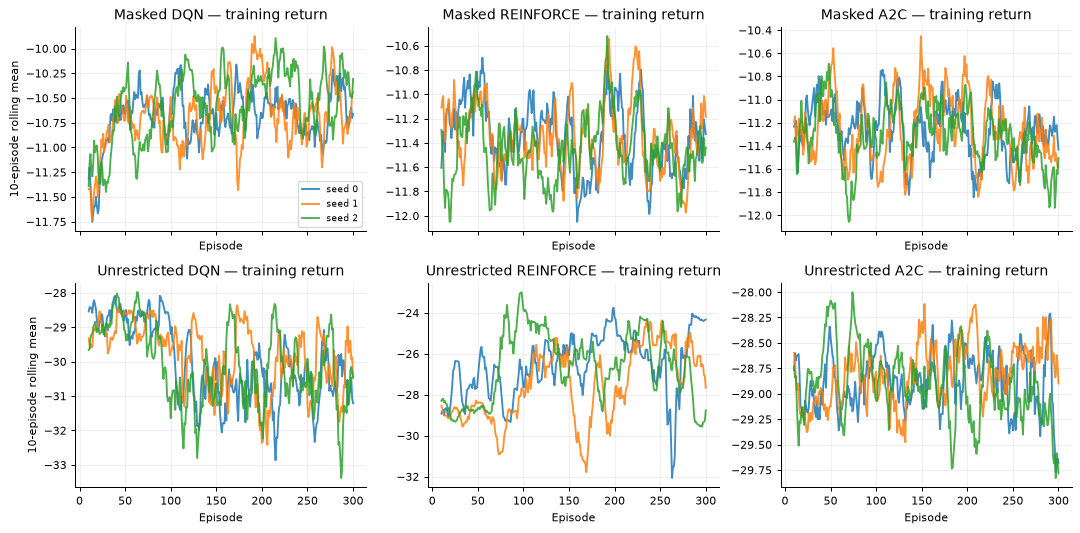

In [19]:
fig, axes = plt.subplots(2,3,figsize=(12,6),sharex=True)
for row, (label, folder) in enumerate([('Masked', HISTORICAL/'masked-study'),
                                      ('Unrestricted', HISTORICAL/'test/unmasked')]):
    for col, algorithm in enumerate(ALGORITHMS):
        ax = axes[row,col]
        for seed in range(3):
            history = pd.read_csv(folder/algorithm/f'seed-{seed}'/'training.csv')
            ax.plot(history['episode'], history['return'].rolling(10,min_periods=10).mean(),
                    label=f'seed {seed}',alpha=0.85)
        ax.set_title(f'{label} {algorithm.upper()} — training return')
        ax.set_xlabel('Episode'); ax.grid(alpha=0.2)
axes[0,0].set_ylabel('10-episode rolling mean'); axes[1,0].set_ylabel('10-episode rolling mean')
axes[0,0].legend(fontsize=7)
finish_plot(fig)

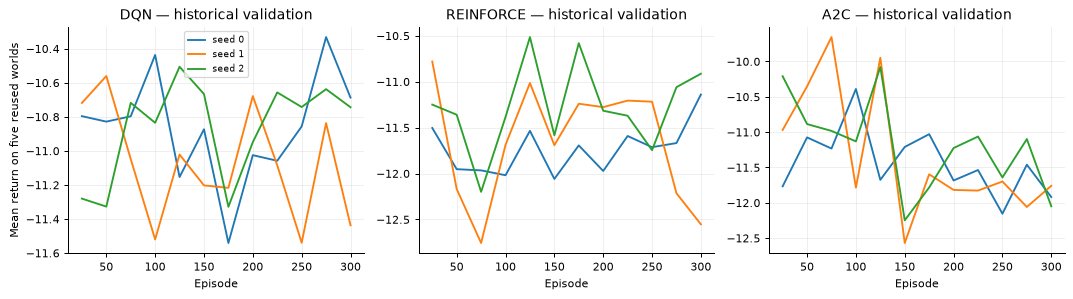

In [20]:
fig, axes = plt.subplots(1,3,figsize=(12,3.4))
for ax, algorithm in zip(axes, ALGORITHMS):
    for seed in range(3):
        v = pd.read_csv(HISTORICAL/'masked-study'/algorithm/f'seed-{seed}'/'validation.csv')
        curve = v.groupby('episode')['return'].mean()
        ax.plot(curve.index,curve.values,label=f'seed {seed}')
    ax.set_title(f'{algorithm.upper()} — historical validation'); ax.set_xlabel('Episode')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('Mean return on five reused worlds'); axes[0].legend(fontsize=7)
finish_plot(fig)

### Experiment code: masked versus unmasked agents

The function below is the experiment behind the table above: each algorithm is trained with
and without the mask under the same settings (development environment, per-agent settings
from `configs/frozen-settings.json`, 300 episodes, seeds 0–2) and evaluated on test worlds
10000–10019. The full rerun is opt-in; the short demonstration underneath trains DQN for ten
episodes both ways and shows the effect on fleet survival immediately.

In [21]:
dev_env = EnvConfig(**development['environment'])
historical_settings = json.loads((REPO/'configs/frozen-settings.json').read_text())


def mask_comparison(algorithm, seeds=(0, 1, 2), episodes=300, worlds=range(10000, 10020)):
    rows = []
    for masked in (True, False):
        for seed in seeds:
            t = TrainConfig(**(development['training'] | historical_settings[algorithm] |
                               {'episodes': episodes, 'seed': seed, 'progress_interval': 0}))
            model, _ = train_agent(algorithm, dev_env, t, masked=masked, verbose=False)
            name = ('masked ' if masked else 'unmasked ') + algorithm
            rows += [run_episode(dev_env, NeuralPolicy(model, masked), w, name=name,
                                 training_seed=seed) for w in worlds]
    return pd.DataFrame(rows)


if RUN_MASK_COMPARISON:
    rerun = pd.concat([mask_comparison(a) for a in ALGORITHMS])
    display(rerun.groupby('policy')[['return', 'weighted_freshness', 'total_losses']].mean())

demo = mask_comparison('dqn', seeds=(0,), episodes=10, worlds=range(10000, 10005))
display(demo.groupby('policy')[['return', 'weighted_freshness', 'total_losses',
                                'charge_completions']].mean()
        .rename_axis('10-episode DQN demonstration (5 test worlds)'))

,return,weighted_freshness,total_losses,charge_completions
10-episode DQN demonstration (5 test worlds),,,,
masked dqn,-10.91284,0.14332,0.0,3.8
unmasked dqn,-27.37854,0.06662,2.6,0.0


## 9. Hyperparameter tuning

**Author: _(name)_**

We tuned in two stages. At 20×20 a
one-seed screen varied each agent's main hyperparameters (200 episodes, five validation
worlds). At 40×40 a learning-rate sweep trained each agent at three rates, 3× either side of
the main-study rate (one seed, 300 episodes, 20 separate validation worlds 23000–23019).

### 9.1 20×20 development screen

In [22]:
tuning = pd.read_csv(HISTORICAL/'tuning.csv')
display(tuning)

,algorithm,parameter,value,seed,final_validation_return,final_validation_freshness,final_validation_losses,best_validation_return,last100_training_return
0,dqn,learning_rate,0.0001,0,-10.49600,0.15507,0.0,-10.49600,-10.85430
1,dqn,learning_rate,0.0003,0,-11.02511,0.14302,0.0,-10.43672,-10.62000
2,dqn,learning_rate,0.0010,0,-10.48968,0.15764,0.0,-10.23602,-10.51434
3,reinforce,learning_rate,0.0001,0,-11.95472,0.11415,0.0,-11.39313,-11.34239
4,reinforce,learning_rate,0.0003,0,-11.97229,0.11450,0.0,-11.50417,-11.35903
5,reinforce,learning_rate,0.0010,0,-11.69515,0.13061,0.0,-11.10807,-10.96598
6,reinforce,entropy_weight,0.0000,0,-11.51570,0.13172,0.0,-10.66877,-11.30294
7,reinforce,entropy_weight,0.0100,0,-11.97229,0.11450,0.0,-11.50417,-11.35903
8,reinforce,entropy_weight,0.0500,0,-11.90709,0.11651,0.0,-11.15353,-11.30510
9,a2c,learning_rate,0.0001,0,-11.15200,0.13154,0.0,-10.86809,-11.33794


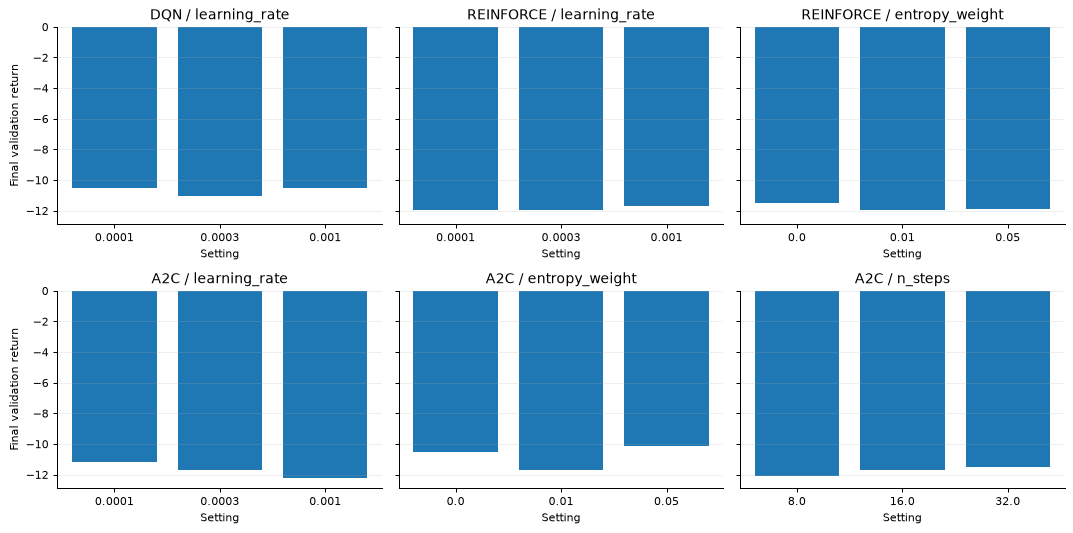

In [23]:
panels = list(tuning.groupby(['algorithm','parameter'],sort=False))
fig, axes = plt.subplots(2,3,figsize=(12,6),sharey=True)
for ax, ((algorithm, parameter),group) in zip(axes.flat,panels):
    ax.bar(group['value'].astype(str),group['final_validation_return'])
    ax.set_title(f'{algorithm.upper()} / {parameter}'); ax.set_xlabel('Setting')
    ax.grid(axis='y',alpha=0.2)
for ax in list(axes.flat)[len(panels):]: ax.set_visible(False)
axes[0,0].set_ylabel('Final validation return'); axes[1,0].set_ylabel('Final validation return')
finish_plot(fig)

### 9.2 40×40 learning-rate sweep

In [24]:
def learning_rate_sweep(algorithm, factors=(1/3, 1, 3), worlds=range(23000, 23020), seed=0):
    """Train one fit per learning rate with every other setting frozen, then evaluate."""
    base = TrainConfig(**frozen['training'][algorithm], seed=seed)
    rows = []
    for factor in factors:
        rate = float(f'{base.learning_rate*factor:.0e}')
        model, _ = train_agent(algorithm, main_env,
                                replace(base, learning_rate=rate, progress_interval=0),
                                verbose=False)
        policy = NeuralPolicy(model)
        rows += [dict(learning_rate=rate, **run_episode(main_env, policy, w, name=algorithm,
                                                        training_seed=seed)) for w in worlds]
    return pd.DataFrame(rows)


if RUN_SWEEP:
    rerun = pd.concat([learning_rate_sweep(a) for a in ALGORITHMS])
    display(rerun.groupby(['policy', 'learning_rate'])[
        ['return', 'weighted_freshness', 'overdue_fraction']].mean())

sweep = pd.read_csv(FOLLOW_UP/'lr_sweep_summary.csv')
display(sweep[['policy', 'learning_rate', 'frozen_rate', 'weighted_freshness_mean',
               'overdue_fraction_mean', 'return_mean', 'total_losses_mean']])

,policy,learning_rate,frozen_rate,weighted_freshness_mean,overdue_fraction_mean,return_mean,total_losses_mean
0,dqn,0.00003,False,0.08685,0.86807,-24.70810,0.0
1,dqn,0.00010,True,0.09807,0.84900,-23.99862,0.0
2,dqn,0.00030,False,0.08038,0.87907,-25.19288,0.0
3,reinforce,0.00030,False,0.07149,0.88977,-25.65658,0.0
4,reinforce,0.00100,True,0.07989,0.88115,-25.21526,0.0
5,reinforce,0.00300,False,0.08397,0.86825,-24.80307,0.0
6,a2c,0.00003,False,0.08393,0.86694,-24.69713,0.0
7,a2c,0.00010,True,0.08353,0.86645,-24.71959,0.0
8,a2c,0.00030,False,0.08249,0.86900,-24.83689,0.0
9,greedy,NaN,NaN,0.22580,0.64447,-15.64728,0.0


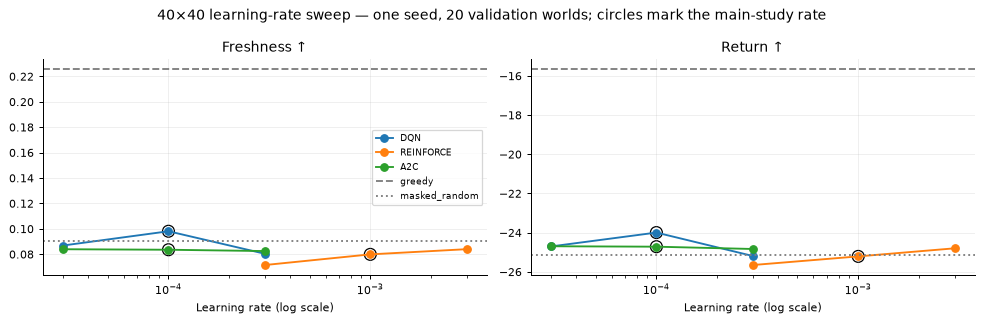

In [25]:
refs = sweep[sweep['learning_rate'].isna()].set_index('policy')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric, label in zip(axes, ['weighted_freshness_mean', 'return_mean'],
                             ['Freshness ↑', 'Return ↑']):
    for algorithm in ALGORITHMS:
        rows = sweep[sweep['policy'] == algorithm].sort_values('learning_rate')
        ax.plot(rows['learning_rate'], rows[metric], marker='o', label=algorithm.upper())
        frozen_row = rows[rows['frozen_rate'] == True]  # noqa: E712
        ax.scatter(frozen_row['learning_rate'], frozen_row[metric], s=90, facecolors='none',
                   edgecolors='black')
    for name, style in [('greedy', '--'), ('masked_random', ':')]:
        ax.axhline(refs.loc[name, metric], color='grey', linestyle=style, label=name)
    ax.set_xscale('log'); ax.set_xlabel('Learning rate (log scale)'); ax.set_title(label)
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=7)
fig.suptitle('40×40 learning-rate sweep — one seed, 20 validation worlds; circles mark the main-study rate')
finish_plot(fig)

**Effect of tuning.** None of the tested rates closed the gap to Greedy in these seed-0
runs: the best fit (DQN at its main-study rate) reached 0.098 freshness against Greedy's
0.226. That fit is slightly ahead of masked random on freshness (0.0981 against 0.0906) and
return (−24.00 against −25.14), and six of the nine fits have a better return than masked
random, but the freshness gap is smaller than the SD across worlds (about 0.015). REINFORCE
improved with a larger rate and A2C was flat over a 10-fold range. With one seed per setting,
differences of about 0.01 are within the seed-to-seed spread of the main study, so the
ordering of rates is only suggestive, and one seed cannot rule out the learning rate as a
contributing cause. What the sweep shows is that a 3-fold change either way was not enough
on its own.

The nine sweep checkpoints are published as the GitHub release
`lr-sweep-checkpoints-2026-10-11`, with their SHA-256 hashes in
`experiments/lithma/results/lr_sweep/SHA256SUMS`. Retraining gives slightly different weights
on a different machine, so these files are what reproduce the table above exactly.

## 10. Main 40×40 study

**Author: _(name)_**

The main comparison is complete. The corrected implementation, all settings and the budget were fixed before any main-study fit started. It is a distinct fixed-budget RL study, independently initialized without supervised warm starts.

| Item | Frozen design |
| --- | --- |
| Algorithms and fits | DQN, REINFORCE, A2C × seeds 0,1,2 = nine main fits |
| Training | 300 episodes per fit; worlds 0–299 |
| Final evaluation | Fresh worlds 22000–22019; every final model and all four baselines |
| Checkpoint selection | Final checkpoint only; no validation split or best-seed selection |
| Reward and observations | Original reward, complete state, spatial location encoding |
| Mask | Feasible candidate actions plus emergency return fallback; shared with masked random |
| Budget | Equal episode budget; completed interactions and updates reported separately |
| Evaluation decisions | Deterministic masked first-index argmax for learners |
| Runtime | One PyTorch CPU thread; no claim that GPU improves learning |

All nine fits finished before final evaluation. Earlier draft targets of five seeds and 100 test worlds were reduced to three seeds and 20 worlds; this executed scope is disclosed. Twenty worlds per fitted model do not create twenty independent trained models. No 60×60 result or cross-grid transfer is claimed.

In [26]:
protocol = json.loads((MAIN/'launch.json').read_text())
audit = json.loads((MAIN/'audit.json').read_text())
completion = json.loads((MAIN/'completion.json').read_text())
assert protocol['source_revision'] == audit['source_revision'] == FROZEN_SOURCE
assert protocol['env_config'] == frozen['environment']
assert not set(range(300)) & set(frozen['evaluation_worlds'])
settings_table = pd.DataFrame(frozen['training']).loc[
    ['episodes','learning_rate','gamma','batch_size','replay_size','warmup_steps',
     'target_update_steps','epsilon_start','epsilon_end','epsilon_decay_steps','n_steps','entropy_weight','value_weight',
     'max_grad_norm','device','double_dqn','coordination_shaping_weight','validation_seeds']]
display(pd.DataFrame({'20×20 historical': EnvConfig(**development['environment']).to_dict(),
                      '40×40 main': frozen['environment']}))
display(settings_table)
fit_table = pd.DataFrame(audit['fits'])
display(fit_table)
assert len(fit_table)==9 and (fit_table['episodes']==300).all() and (fit_table['steps']==90000).all()
print('Total recorded training interactions:',int(fit_table['steps'].sum()))

,20×20 historical,40×40 main
grid_size,20.00,40.00
horizon,160.00,300.00
battery_capacity,80.00,160.00
move_cost,1.00,1.00
hover_cost,0.25,0.25
recharge_rate,5.00,8.00
sensor_radius,1.00,2.00
inspection_deadline,25.00,30.00
max_fuel,100.00,180.00
initial_fires,3.00,3.00


,dqn,reinforce,a2c
episodes,300,300,300
learning_rate,0.0001,0.001,0.0001
gamma,0.99,0.99,0.99
batch_size,32,32,32
replay_size,2000,2000,2000
warmup_steps,128,128,128
target_update_steps,100,100,100
epsilon_start,1.0,1.0,1.0
epsilon_end,0.05,0.05,0.05
epsilon_decay_steps,40000,40000,40000


,algorithm,seed,episodes,steps,updates,training_seconds
0,dqn,0,300,90000,89873,1133.68977
1,dqn,1,300,90000,89873,1460.62276
2,dqn,2,300,90000,89873,1449.95601
3,reinforce,0,300,90000,300,115.27974
4,reinforce,1,300,90000,300,216.14375
5,reinforce,2,300,90000,300,219.50333
6,a2c,0,300,90000,3000,215.88282
7,a2c,1,300,90000,3000,220.40896
8,a2c,2,300,90000,3000,221.33301


Total recorded training interactions: 810000


In [27]:
# Retrain the frozen DQN seed-0 fit and compare it with the archived training curve.
# Exact equality holds only on the archive's hardware and software (a GitHub Linux runner).
# On another CPU the first episode matches (to ~1e-15, float rounding); once updates start, tiny
# floating-point differences grow, so later returns differ slightly. This is expected.
if RUN_TRAINING:
    model, rows = train_agent('dqn', main_env, TrainConfig(**frozen['training']['dqn'], seed=0))
    archived = pd.read_csv(MAIN/'fits/dqn/seed-0/training.csv')
    difference = (pd.DataFrame(rows)['return']-archived['return']).abs()
    print('Episode 1 return difference:', difference.iloc[0])
    print('Largest return difference over all episodes:', difference.max())

### Training curves

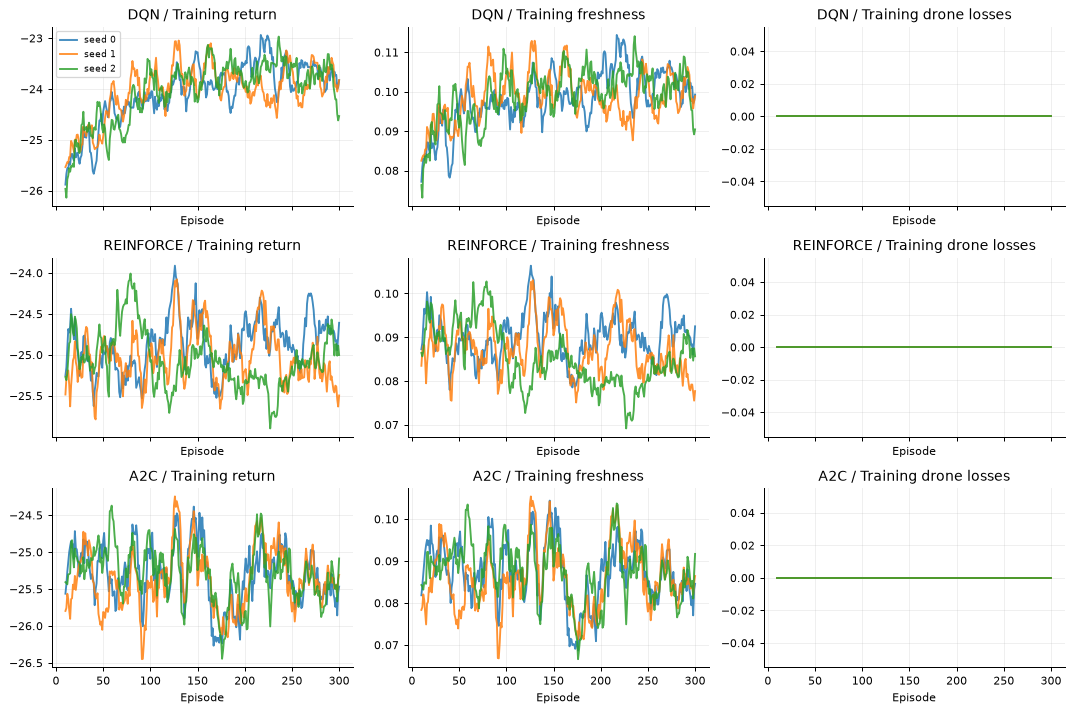

last 50 return  last 50 weighted_freshness  \
algorithm fit_seed                                               
a2c       0              -25.45594                     0.08461   
          1              -25.36870                     0.08556   
          2              -25.43039                     0.08497   
dqn       0              -23.65287                     0.10288   
          1              -23.83966                     0.09933   
          2              -23.90091                     0.09920   
reinforce 0              -24.68329                     0.09157   
          1              -25.23004                     0.08275   
          2              -25.00035                     0.08476   

                    last 50 total_losses  
algorithm fit_seed                        
a2c       0                          0.0  
          1                          0.0  
          2                          0.0  
dqn       0                          0.0  
          1                          0.0  
          2                          0.0  
reinforce 0                          0.0  
          1                          0.0  
          2                          0.0

Training curves describe sampled behavior on changing training worlds, not final generalization.


In [28]:
main_history = []
for algorithm in ALGORITHMS:
    for seed in range(3):
        frame = pd.read_csv(MAIN/'fits'/algorithm/f'seed-{seed}'/'training.csv')
        assert len(frame)==300 and frame['scenario_seed'].tolist()==list(range(300))
        main_history.append(frame.assign(algorithm=algorithm,fit_seed=seed))
main_history = pd.concat(main_history,ignore_index=True)
fig, axes = plt.subplots(3,3,figsize=(12,8),sharex=True)
metrics = [('return','Training return'),('weighted_freshness','Training freshness'),
           ('total_losses','Training drone losses')]
for row,algorithm in enumerate(ALGORITHMS):
    for col,(metric,label) in enumerate(metrics):
        ax = axes[row,col]
        for seed in range(3):
            frame = main_history.query('algorithm == @algorithm and fit_seed == @seed')
            ax.plot(frame['episode'],frame[metric].rolling(10,min_periods=10).mean(),
                    label=f'seed {seed}',alpha=0.85)
        ax.set_title(f'{algorithm.upper()} / {label}'); ax.set_xlabel('Episode')
        ax.grid(alpha=0.2)
axes[0,0].legend(fontsize=7)
finish_plot(fig)
last_window = main_history[main_history['episode']>250].groupby(['algorithm','fit_seed'])[
    ['return','weighted_freshness','total_losses']].mean()
display(last_window.rename(columns=lambda c:'last 50 '+c))
print('Training curves describe sampled behavior on changing training worlds, not final generalization.')

### What these curves establish

Each fit completed 90,000 interactions. DQN made 89,873 optimizer updates; REINFORCE made 300 episode updates; A2C made 3,000 segment updates. Equal interactions do not imply equal optimization work or CPU time. Return curves alone do not prove convergence, calibrated Q values or optimality. No additional fits are triggered by their shape.

Stochastic actor sampling during training and deterministic argmax at evaluation are different policies. Their mismatch is a plausible contributor to poor evaluation; the historical sampled-actor diagnostic also failed, so changing evaluation mode alone is not an established solution. Main final evaluation remains the frozen deterministic rule.

### Final evaluation on 20 fresh worlds

We first average the 20 world outcomes within each fitted seed, then average the three fitted-seed means. Learner sample SD is across those three means. Baseline mean and sample SD are across 20 worlds. These units are different. No confidence intervals or statistical significance claims are inferred from the displayed SDs.

The paired table retains the same world for each learner/baseline difference. It is descriptive; repeated worlds across fit seeds do not turn 60 learner missions into 60 independent training replicates. Every final fitted policy is shown, not just the best seed.

In [29]:
episodes = pd.read_csv(MAIN/'episodes.csv')
archived_summary = pd.read_csv(MAIN/'summary.csv')
comparison = pd.read_csv(MAIN/'comparison.csv')
paired = pd.read_csv(MAIN/'paired.csv')
assert len(episodes)==260 and set(episodes['scenario_seed'])==set(frozen['evaluation_worlds'])
assert not episodes.duplicated(['policy','training_seed','scenario_seed']).any()
assert len(paired)==720
assert episodes.query('policy in @ALGORITHMS').shape[0]==180
assert episodes.query('policy not in @ALGORITHMS').shape[0]==80
metrics = ['return','weighted_freshness','overdue_fraction','total_losses',
           'fleet_failure','intact_fleet','energy_used','safe_returns','charge_completions',
           'collision_attempts','steps','decision_ms']
rows = []
for policy in POLICIES:
    frame = episodes[episodes['policy']==policy]
    units = frame.groupby('training_seed')[metrics].mean() if policy in ALGORITHMS else frame[metrics]
    if policy in ALGORITHMS:
        assert len(units)==3 and set(frame['training_seed'])=={0,1,2}
        assert frame.groupby('training_seed').size().eq(20).all()
    else:
        assert len(units)==20
    for metric in metrics:
        rows.append({'policy':policy,'metric':metric,'unit':'seed_means' if policy in ALGORITHMS
                     else 'worlds','units':len(units),'mean':units[metric].mean(),
                     'sample_sd':units[metric].std(ddof=1)})
recomputed_summary = pd.DataFrame(rows)
check = recomputed_summary.merge(archived_summary,on=['policy','metric'],suffixes=('_new','_archive'))
assert len(check)==len(archived_summary)==len(recomputed_summary)
assert np.allclose(check['mean_new'],check['mean_archive'],rtol=1e-12,atol=1e-12)
assert np.allclose(check['sample_sd_new'],check['sample_sd_archive'],rtol=1e-12,atol=1e-12)
main_means = recomputed_summary.pivot(index='policy',columns='metric',values='mean').loc[POLICIES]
main_sds = recomputed_summary.pivot(index='policy',columns='metric',values='sample_sd').loc[POLICIES]
display(main_means[['return','weighted_freshness','overdue_fraction','total_losses',
                    'intact_fleet','safe_returns','charge_completions','decision_ms']])
display(recomputed_summary[recomputed_summary['metric'].isin(
    ['return','weighted_freshness','overdue_fraction','total_losses'])])
print('All archived final means and sample SDs reproduced from 260 raw mission rows.')

metric,return,weighted_freshness,overdue_fraction,total_losses,intact_fleet,safe_returns,charge_completions,decision_ms
policy,,,,,,,,
dqn,-24.78568,0.08438,0.86869,0.0,1.0,4.63333,4.56667,0.43076
reinforce,-25.81054,0.06901,0.89402,0.0,1.0,4.00000,4.00000,0.65344
a2c,-24.82772,0.08435,0.86949,0.0,1.0,5.06667,5.06667,0.69247
greedy,-16.10008,0.22077,0.65563,0.0,1.0,3.15000,3.15000,3.16635
sweep,-26.07103,0.06486,0.90121,0.0,1.0,1.00000,1.00000,0.20509
random,-42.87108,0.05956,0.92098,3.0,0.0,3.40000,0.65000,0.00863
masked_random,-25.46148,0.08379,0.88601,0.0,1.0,9.85000,9.80000,0.20628


,policy,metric,unit,units,mean,sample_sd
0,dqn,return,seed_means,3,-24.78568,0.24991
1,dqn,weighted_freshness,seed_means,3,0.08438,0.00254
2,dqn,overdue_fraction,seed_means,3,0.86869,0.00634
3,dqn,total_losses,seed_means,3,0.00000,0.00000
12,reinforce,return,seed_means,3,-25.81054,0.58718
13,reinforce,weighted_freshness,seed_means,3,0.06901,0.00730
14,reinforce,overdue_fraction,seed_means,3,0.89402,0.01567
15,reinforce,total_losses,seed_means,3,0.00000,0.00000
24,a2c,return,seed_means,3,-24.82772,0.91711
25,a2c,weighted_freshness,seed_means,3,0.08435,0.01163


All archived final means and sample SDs reproduced from 260 raw mission rows.


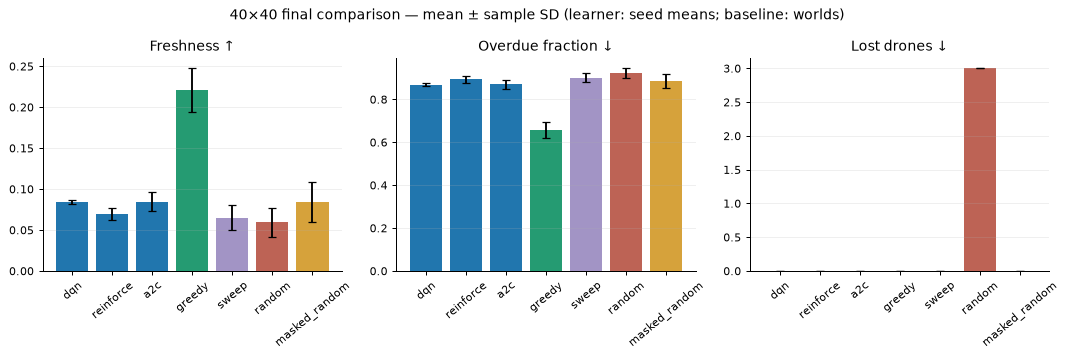

,policy,training_seed,worlds,return,weighted_freshness,overdue_fraction,total_losses,fleet_failure,intact_fleet
0,dqn,0.0,20,-24.53663,0.08713,0.86265,0.0,0.0,1.0
1,dqn,1.0,20,-24.78398,0.08389,0.86812,0.0,0.0,1.0
2,dqn,2.0,20,-25.03645,0.08212,0.87529,0.0,0.0,1.0
3,reinforce,0.0,20,-25.14314,0.07743,0.87637,0.0,0.0,1.0
4,reinforce,1.0,20,-26.24775,0.06435,0.90629,0.0,0.0,1.0
5,reinforce,2.0,20,-26.04074,0.06526,0.89939,0.0,0.0,1.0
6,a2c,0.0,20,-25.88598,0.07094,0.89527,0.0,0.0,1.0
7,a2c,1.0,20,-24.33258,0.09027,0.85751,0.0,0.0,1.0
8,a2c,2.0,20,-24.26461,0.09183,0.85569,0.0,0.0,1.0
9,greedy,NaN,20,-16.10008,0.22077,0.65563,0.0,0.0,1.0


In [30]:
fig,axes = plt.subplots(1,3,figsize=(12,4))
for ax,metric,title in zip(axes,['weighted_freshness','overdue_fraction','total_losses'],
                         ['Freshness ↑','Overdue fraction ↓','Lost drones ↓']):
    ax.bar(POLICIES,main_means[metric],yerr=main_sds[metric],capsize=3,
           color=['#2176ae']*3+['#259b72','#a294c5','#bd6355','#d6a23b'])
    ax.set_title(title); ax.tick_params(axis='x',rotation=40); ax.grid(axis='y',alpha=0.2)
fig.suptitle('40×40 final comparison — mean ± sample SD (learner: seed means; baseline: worlds)')
finish_plot(fig)
display(comparison[['policy','training_seed','worlds','return','weighted_freshness',
                    'overdue_fraction','total_losses','fleet_failure','intact_fleet']])

In [31]:
# Key comparisons quoted in the text
fresh = main_means['weighted_freshness']
masked = main_means.loc['masked_random']
with pd.option_context('display.precision', 6):
    display(pd.DataFrame({
        'Greedy freshness ÷ learner': fresh['greedy']/fresh[ALGORITHMS],
        'learner − masked random (freshness)': fresh[ALGORITHMS]-masked['weighted_freshness'],
        'learner − masked random (return)': main_means.loc[ALGORITHMS, 'return']-masked['return'],
    }))

,Greedy freshness ÷ learner,learner − masked random (freshness),learner − masked random (return)
policy,,,
dqn,2.616287,0.000589,0.675793
reinforce,3.198897,-0.014780,-0.349064
a2c,2.617397,0.000553,0.633755


### Rolling-horizon planner

The proposal promised a comparison with a rolling-horizon planner, which the frozen study did
not run. A follow-up flew `RollingHorizonPolicy` (Section 5) on the same 20 final worlds with
its default settings: 4-step lookahead, 8 candidate first actions (the Greedy action plus 7
random feasible ones), 2 sampled fire futures per candidate, rollouts that continue 75%
Greedy and 25% random, and the final state's freshness added as a small terminal value. The
planner's random numbers are seeded with the world number, like random and masked random.

Before adding new rows to the frozen comparison, the experiment re-flew Greedy, sweep, random
and masked random with the same code and checked that they reproduce the archived
`episodes.csv`, so the planner rows are directly comparable with the archived ones.

In [32]:
FROZEN_BASELINES = ['greedy', 'sweep', 'random', 'masked_random']
final_worlds = frozen['evaluation_worlds']
archived_episodes = pd.read_csv(MAIN/'episodes.csv')
# Every metric except decision_ms, which is wall-clock time and differs between machines.
EXACT = ['return', 'weighted_freshness', 'overdue_fraction', 'energy_used', 'total_losses',
         'safe_returns', 'charge_completions', 'collision_attempts', 'steps', 'fleet_failure',
         'intact_fleet']


def make_baseline(name, world):
    """Every conventional controller by name; the stochastic ones are seeded with the world."""
    return {'greedy': lambda: GreedyPolicy(), 'sweep': lambda: SweepPolicy(),
            'random': lambda: RandomPolicy(world),
            'masked_random': lambda: MaskedRandomPolicy(world),
            'planner': lambda: RollingHorizonPolicy(world)}[name]()


def fly(config, name, worlds):
    return pd.DataFrame([run_episode(config, make_baseline(name, w), w, name=name)
                         for w in worlds])


def harness_check(worlds=final_worlds):
    """Re-fly the archived baselines; largest difference from the archive, per policy."""
    rows = []
    for name in FROZEN_BASELINES:
        new = fly(main_env, name, worlds).set_index('scenario_seed')
        old = archived_episodes[archived_episodes['policy'] == name].set_index('scenario_seed')
        difference = (new[EXACT]-old.loc[new.index, EXACT]).abs().to_numpy().max()
        rows.append({'policy': name, 'worlds': len(new), 'max_abs_difference': difference})
    return pd.DataFrame(rows)


if RUN_PLANNER:
    display(harness_check())
    planner_rows = fly(main_env, 'planner', final_worlds)
else:
    display(pd.read_csv(FOLLOW_UP/'harness_reproduction.csv')[
        ['policy', 'worlds', 'max_abs_difference']].rename_axis('archived harness check'))
    planner_rows = pd.read_csv(FOLLOW_UP/'planner_episodes.csv')

,policy,worlds,max_abs_difference
archived harness check,,,
0,greedy,20,7.77156e-16
1,sweep,20,1.55431e-15
2,random,20,4.44089e-16
3,masked_random,20,7.77156e-16


In [33]:
# Demonstration: re-fly the planner on the first final world (under a minute) and check
# that this notebook reproduces the archived planner mission exactly.
world = final_worlds[0]
again = run_episode(main_env, RollingHorizonPolicy(world), world, name='planner')
archived_row = pd.read_csv(FOLLOW_UP/'planner_episodes.csv').set_index('scenario_seed').loc[world]
assert all(abs(again[m]-archived_row[m]) < 1e-9 for m in EXACT)
print(f"Planner on world {world}: return {again['return']:.3f}, freshness "
      f"{again['weighted_freshness']:.4f}, {again['decision_ms']:.0f} ms per decision "
      f"(identical to the archived run).")

Planner on world 22000: return -18.466, freshness 0.1845, 67 ms per decision (identical to the archived run).


In [34]:
planner = pd.read_csv(FOLLOW_UP/'planner_vs_frozen_table.csv')
display(planner[['policy', 'source', 'weighted_freshness_mean', 'weighted_freshness_sd',
                 'overdue_fraction_mean', 'return_mean', 'total_losses_mean', 'decision_ms_mean']])

# Paired comparison on the same worlds: planner minus Greedy.
greedy_rows = archived_episodes[archived_episodes['policy'] == 'greedy'].set_index('scenario_seed')
planner_by_world = planner_rows.set_index('scenario_seed')
difference = {}
for metric in ['return', 'weighted_freshness', 'overdue_fraction']:
    delta = planner_by_world[metric]-greedy_rows.loc[planner_by_world.index, metric]
    better = (delta < 0) if metric == 'overdue_fraction' else (delta > 0)
    difference[metric] = {'mean difference': delta.mean(), 'SD': delta.std(),
                          'planner better (of 20 worlds)': int(better.sum())}
display(pd.DataFrame(difference).T.rename_axis('planner − Greedy, paired by world'))

,policy,source,weighted_freshness_mean,weighted_freshness_sd,overdue_fraction_mean,return_mean,total_losses_mean,decision_ms_mean
0,dqn,frozen archive,0.08438,0.00254,0.86869,-24.78568,0.0,0.43076
1,reinforce,frozen archive,0.06901,0.00730,0.89402,-25.81054,0.0,0.65344
2,a2c,frozen archive,0.08435,0.01163,0.86949,-24.82772,0.0,0.69247
3,greedy,frozen archive,0.22077,0.02664,0.65563,-16.10008,0.0,3.16635
4,planner,new (this script),0.22070,0.02695,0.66675,-16.55443,0.0,153.68775
5,sweep,frozen archive,0.06486,0.01535,0.90121,-26.07103,0.0,0.20509
6,random,frozen archive,0.05956,0.01779,0.92098,-42.87108,3.0,0.00863
7,masked_random,frozen archive,0.08379,0.02433,0.88601,-25.46148,0.0,0.20628


,mean difference,SD,planner better (of 20 worlds)
"planner − Greedy, paired by world",,,
return,-0.45434,1.17821,7.0
weighted_freshness,-0.00007,0.01780,9.0
overdue_fraction,0.01112,0.02948,7.0


The planner matches Greedy's freshness (0.2207 against 0.2208), has a slightly worse
return (−16.55 against −16.10) and loses no drones, but each decision costs about 60 times
more (67 ms against 1.1 ms in a serial timing check). Looking four steps ahead adds nothing
over the one-step rule in this setting. The archived frozen rows were timed on a GitHub
runner and the planner on a laptop, so the timing columns are indicative only.

### Performance gates and survival

In [35]:
gates = pd.DataFrame([{'algorithm':r['algorithm'],'seed':r['seed'],
                       'learned contribution gate':r['learning_gate_passed'],
                       'Greedy capability gate':r['greedy_gate_passed'],
                       **{'mask: '+k:v for k,v in r['masked_random_checks'].items()},
                       **{'Greedy: '+k:v for k,v in r['greedy_checks'].items()}}
                      for r in completion['per_fit']])
display(gates)
assert len(gates)==9 and not gates['learned contribution gate'].any()
assert not gates['Greedy capability gate'].any()
survival = episodes.groupby('policy').agg(missions=('intact_fleet','size'),
    intact_fleet_missions=('intact_fleet','sum'),failed_fleet_missions=('fleet_failure','sum'),
    mean_lost_drones=('total_losses','mean')).loc[POLICIES]
display(survival)
print('Comparison completed:',completion['comparison_complete'])
print('Performance gates passed:',int(gates['learned contribution gate'].sum()),'of 9')

,algorithm,seed,learned contribution gate,Greedy capability gate,mask: freshness_ge_masked_random_plus_001,mask: return_ge_masked_random_plus_05,mask: losses_le_masked_random,mask: failures_le_masked_random,Greedy: freshness_ge_90pct_greedy,Greedy: overdue_le_greedy_plus_005,Greedy: losses_le_greedy_plus_01,Greedy: failures_le_greedy
0,dqn,0,False,False,False,True,True,True,False,False,True,True
1,dqn,1,False,False,False,True,True,True,False,False,True,True
2,dqn,2,False,False,False,False,True,True,False,False,True,True
3,reinforce,0,False,False,False,False,True,True,False,False,True,True
4,reinforce,1,False,False,False,False,True,True,False,False,True,True
5,reinforce,2,False,False,False,False,True,True,False,False,True,True
6,a2c,0,False,False,False,False,True,True,False,False,True,True
7,a2c,1,False,False,False,True,True,True,False,False,True,True
8,a2c,2,False,False,False,True,True,True,False,False,True,True


,missions,intact_fleet_missions,failed_fleet_missions,mean_lost_drones
policy,,,,
dqn,60,60,0,0.0
reinforce,60,60,0,0.0
a2c,60,60,0,0.0
greedy,20,20,0,0.0
sweep,20,20,0,0.0
random,20,0,20,3.0
masked_random,20,20,0,0.0


Comparison completed: True
Performance gates passed: 0 of 9


The learning gate requires every fit to achieve freshness ≥ masked random +0.01, return ≥ masked random +0.5 and no worse losses/fleet failures. The Greedy gate separately requires ≥90% of Greedy freshness, overdue ≤ Greedy +0.05, losses ≤ Greedy +0.1 and no worse fleet failures. These are predeclared project criteria, not assignment grading requirements. All nine fitted policies failed both complete gates.

All 180 learned missions retained the fleet. Masked random retained it in all 20 missions. Unrestricted random lost all three drones in all 20 missions. DQN and A2C mean freshness exceeded masked random by only about 0.0006; that small descriptive difference does not establish a useful learned contribution. Greedy has the best mean freshness and return in this final comparison.

In [36]:
display(pd.DataFrame([{'audit item':k,'recorded result':str(v)} for k,v in audit.items()
                     if k!='fits']))
assert audit['passed'] and audit['initial_tensors_verified']
assert audit['every_action_mask_hash_reward_exact'] and audit['negative_archives_unchanged']
assert audit['mission_episodes']==len(episodes)
assert audit['mission_steps']==int(episodes['steps'].sum())==75911
assert audit['paired_rows']==len(paired) and audit['max_score_drift']==0.0
print('Recorded independent replay: 75,911 steps, exact actions/masks/hashes/rewards, zero neural-score drift.')
print('This notebook checks records and aggregates; it does not claim to replay binary checkpoints here.')

,audit item,recorded result
0,passed,True
1,source_revision,855e5510ff46b16082ab7d551e7c228acab6f572
2,mission_episodes,260
3,mission_steps,75911
4,paired_rows,720
5,every_action_mask_hash_reward_exact,True
6,negative_archives_unchanged,True
7,initial_tensors_verified,True
8,max_score_drift,0.0
9,score_atol,1e-05


Recorded independent replay: 75,911 steps, exact actions/masks/hashes/rewards, zero neural-score drift.
This notebook checks records and aggregates; it does not claim to replay binary checkpoints here.


An independent replay of all 75,911 evaluation steps reproduced every action, feasible
mask, state hash and reward, with zero drift in network scores. The trained weights are kept
as GitHub Actions artifacts with 90-day retention; the learning-rate sweep's nine fits are kept
permanently as a GitHub release (Section 9.2).

## 11. Sensitivity to battery, charging and fire spread

**Author: _(name)_**

The nine
trained learners and the baselines were flown again on the same 20 worlds with one setting
changed at a time (no retraining). Learner rows therefore measure robustness of fixed weights,
not what an agent would learn under the new setting.

Each setting is lowered and raised once around the main-study value, giving seven
conditions in total (the default is shared):

| Setting | Low | Default | High |
| --- | ---: | ---: | ---: |
| Battery capacity | 120 | 160 | 200 |
| Recharge rate (battery units per charging step) | 5 | 8 | 12 |
| Fire spread probability | 0.02 | 0.04 | 0.08 |

A world seed fixes the terrain, fuel, priority areas, ignitions and the fire's random draws,
and none of these settings changes how many random numbers the environment uses, so every
condition sees the same 20 worlds apart from the changed setting. The policies are Greedy, the
planner, masked random, sweep and the nine trained main-study learners (DQN, REINFORCE and A2C
× training seeds 0–2), giving 1,820 missions. A learner's battery input is normalised by the
current capacity, and its feasibility mask is recomputed from the current setting.

In [37]:
SENSITIVITY = {'battery_capacity': (120, 200), 'recharge_rate': (5, 12),
               'spread_probability': (0.02, 0.08)}


def frozen_learner(algorithm, seed):
    """Weights of one main-study fit, if downloaded and byte-identical to the archived hash."""
    path = FROZEN_CHECKPOINTS/f'{algorithm}-{seed}/fits/{algorithm}/seed-{seed}/policy.pt'
    record = json.loads((MAIN/f'fit-{algorithm}-{seed}.json').read_text())
    if (not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest()
            != record['files']['policy.pt']['sha256']):
        return None
    data = torch.load(path, map_location='cpu', weights_only=True)
    model = FleetNetwork(data['env_config']['grid_size'], **data['model_config'])
    model.load_state_dict(data['state_dict'])
    return model


def sensitivity_study(worlds=final_worlds):
    """Fly every policy under each condition; learners keep their default-setting weights."""
    conditions = [('default', {})] + [(f'{p}={v}', {p: v})
                                      for p, values in SENSITIVITY.items() for v in values]
    learners = {(a, s): frozen_learner(a, s) for a in ALGORITHMS for s in range(3)}
    learners = {key: model for key, model in learners.items() if model is not None}
    print(f'{len(learners)}/9 main-study learner checkpoints found; missing ones are skipped.')
    rows = []
    for condition, overrides in conditions:
        config = replace(main_env, **overrides)
        for name in ['greedy', 'planner', 'masked_random', 'sweep']:
            rows += [dict(condition=condition, **run_episode(config, make_baseline(name, w), w,
                                                             name=name)) for w in worlds]
        for (algorithm, seed), model in learners.items():
            policy = NeuralPolicy(model)  # no retraining under the changed setting
            rows += [dict(condition=condition, **run_episode(config, policy, w, name=algorithm,
                                                             training_seed=seed))
                     for w in worlds]
    return pd.DataFrame(rows)


if RUN_SENSITIVITY:
    rerun = sensitivity_study()
    display(rerun.groupby(['condition', 'policy'])['weighted_freshness'].mean().unstack())

In [38]:
sensitivity = pd.read_csv(FOLLOW_UP/'sensitivity_summary.csv')
order = ['default', 'battery_capacity=120', 'battery_capacity=200', 'recharge_rate=5',
         'recharge_rate=12', 'spread_probability=0.02', 'spread_probability=0.08']
columns = ['greedy', 'planner', 'masked_random', 'sweep'] + ALGORITHMS
for metric in ['weighted_freshness_mean', 'return_mean']:
    table = sensitivity.pivot(index='condition', columns='policy', values=metric)
    display(table.loc[order, [c for c in columns if c in table.columns]].rename_axis(metric))

per_mission = pd.read_csv(FOLLOW_UP/'sensitivity_episodes.csv')
failures = per_mission.groupby(['condition', 'policy'])['fleet_failure'].sum().unstack(fill_value=0)
display(failures.loc[:, failures.sum() > 0].rename_axis('whole-fleet losses (of 20 or 60)'))

policy,greedy,planner,masked_random,sweep,dqn,reinforce,a2c
weighted_freshness_mean,,,,,,,
default,0.22077,0.22070,0.08379,0.06486,0.08438,0.06901,0.08435
battery_capacity=120,0.20490,0.20826,0.08336,0.06645,0.09640,0.08293,0.09389
battery_capacity=200,0.21508,0.21604,0.08773,0.06432,0.07770,0.06084,0.07526
recharge_rate=5,0.20253,0.20677,0.07797,0.06384,0.08047,0.06563,0.08035
recharge_rate=12,0.22584,0.22741,0.08720,0.06537,0.08482,0.07104,0.08487
spread_probability=0.02,0.20803,0.21619,0.08045,0.06574,0.08444,0.06869,0.08411
spread_probability=0.08,0.20824,0.21392,0.08210,0.06561,0.08565,0.06620,0.08416


policy,greedy,planner,masked_random,sweep,dqn,reinforce,a2c
return_mean,,,,,,,
default,-16.10008,-16.55443,-25.46148,-26.07103,-24.78568,-25.81054,-24.82772
battery_capacity=120,-17.75697,-17.13002,-25.53131,-26.01121,-24.00779,-24.97851,-24.21645
battery_capacity=200,-16.45535,-16.86747,-25.18562,-26.06901,-25.22400,-26.40955,-25.44269
recharge_rate=5,-17.29041,-17.37273,-25.78597,-26.14000,-25.02815,-26.08641,-25.08698
recharge_rate=12,-15.70483,-16.04414,-25.27338,-26.03586,-24.73237,-25.67172,-24.78702
spread_probability=0.02,-17.59752,-16.72727,-25.63382,-26.01616,-24.76610,-25.83351,-24.84324
spread_probability=0.08,-18.23499,-16.75603,-25.55169,-26.02335,-24.67403,-25.99615,-24.83393


policy,greedy
whole-fleet losses (of 20 or 60),
battery_capacity=120,1
battery_capacity=200,0
default,0
recharge_rate=12,0
recharge_rate=5,0
spread_probability=0.02,1
spread_probability=0.08,2


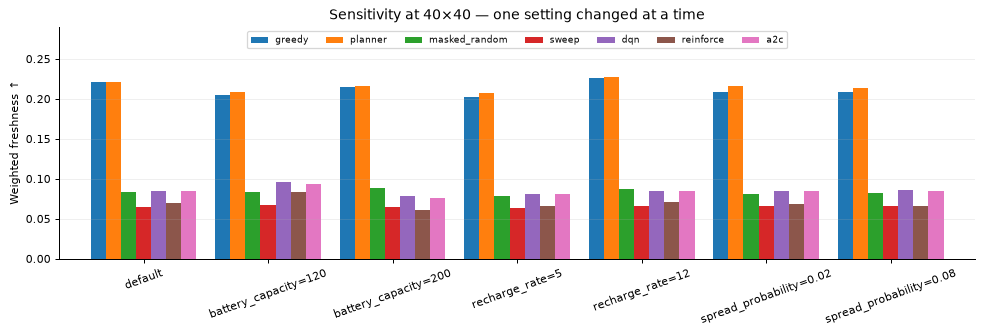

In [39]:
table = sensitivity.pivot(index='condition', columns='policy', values='weighted_freshness_mean')
table = table.loc[order, [c for c in columns if c in table.columns]]
fig, ax = plt.subplots(figsize=(11, 3.8))
table.plot.bar(ax=ax, width=0.85)
ax.set_ylabel('Weighted freshness ↑'); ax.set_xlabel('')
ax.set_title('Sensitivity at 40×40 — one setting changed at a time')
ax.grid(axis='y', alpha=0.2); ax.set_ylim(0, 0.29)
ax.legend(fontsize=7, ncol=7, loc='upper center')
plt.xticks(rotation=20)
finish_plot(fig)

In [40]:
# Demonstration: one of Greedy's whole-fleet losses, reproduced (battery 120, world 22003).
lost = run_episode(replace(main_env, battery_capacity=120), GreedyPolicy(), 22003, name='greedy')
print(f"Greedy, battery 120, world 22003: {lost['total_losses']} drones lost, mission over "
      f"after {lost['steps']} of {main_env.horizon} steps.")
assert lost['fleet_failure'] == 1

# Greedy's return with and without its whole-fleet losses.
greedy_missions = per_mission[per_mission['policy'] == 'greedy']
display(pd.DataFrame({
    'whole-fleet losses': greedy_missions.groupby('condition')['fleet_failure'].sum(),
    'return, all missions': greedy_missions.groupby('condition')['return'].mean(),
    'return, intact missions': greedy_missions[greedy_missions['intact_fleet'] == 1]
    .groupby('condition')['return'].mean()}).loc[order].rename_axis('Greedy'))

Greedy, battery 120, world 22003: 3 drones lost, mission over after 132 of 300 steps.


,whole-fleet losses,"return, all missions","return, intact missions"
Greedy,,,
default,0,-16.10008,-16.10008
battery_capacity=120,1,-17.75697,-16.70343
battery_capacity=200,0,-16.45535,-16.45535
recharge_rate=5,0,-17.29041,-17.29041
recharge_rate=12,0,-15.70483,-15.70483
spread_probability=0.02,1,-17.59752,-16.59363
spread_probability=0.08,2,-18.23499,-16.03100


**Greedy and the planner remain the strongest group across all tested conditions.** They
stay at 0.20–0.23 freshness in every condition; the learners, masked random and sweep stay at
0.06–0.10. Rankings inside each group do change: Greedy leads the planner on freshness only
at the default, and DQN, A2C and masked random swap places from one condition to the next.

- **Charging.** Slower charging costs Greedy and the planner about 0.015–0.018 freshness;
  faster charging helps them a little (0.221 to 0.226–0.227).
- **Whole-fleet losses.** Away from the default settings Greedy lost its whole fleet in 4 of
  140 missions (battery 120 and both spread settings): three low-battery drones met near the
  base, every move home collided, its rule fell back to "all stay", and they hovered until
  empty. This is the deadlock shown in Section 5. The masked learners avoid it through the
  emergency return, and the planner avoided it in all 140 of its missions. No other policy
  lost a drone.
- **Why the planner's return holds up.** Those four failures explain most of Greedy's drop in
  return: on the missions it completes intact, its return stays close to the default. So the
  planner's better return under changed spread is robustness to this failure, not better
  inspection.
- **Battery size and the fixed learners.** A smaller battery makes the unchanged learners
  look better (DQN 0.084 to 0.096) and a larger one worse (0.078). The weights did not change
  and the battery input is normalised, so this is most likely the mask forcing earlier
  returns and more passes near the base, not learned behaviour; that explanation was not
  tested.
- **Fire spread** has almost no effect on the learners, masked random or sweep.

## 12. Critical review

**Author: _(name)_**

### Why the learners stay near masked random: a weak reward signal

All three agents learn from differences in reward between actions. The cell below measures
how large those differences are. Under random feasible play, every tenth step it tries every
feasible joint action from the same state and records its immediate reward (the reward is
computed before the fire evolves, so it is exact for each action). It compares that spread
with how much a whole mission's return varies from world to world under the same behaviour.

In [41]:
def reward_signal(config, worlds, every=10, seed=0):
    rng = np.random.default_rng(seed)
    spread, gap, action_sd, returns = [], [], [], []
    for world in worlds:
        env = WildfireFleetEnv(config)
        env.reset(seed=world)
        done, total = False, 0.0
        while not done:
            feasible = np.flatnonzero(action_mask(env))
            if env.elapsed % every == 0 and len(feasible) > 1:
                rewards = np.sort([copy.deepcopy(env).step(int(a))[1] for a in feasible])
                spread.append(rewards[-1]-rewards[0])   # best minus worst action
                gap.append(rewards[-1]-rewards[-2])     # best minus second-best action
                action_sd.append(rewards.std())
            _, reward, done, _, _ = env.step(int(rng.choice(feasible)))
            total += reward
        returns.append(total)
    return {'best − worst action': np.mean(spread), 'best − second action': np.mean(gap),
            'SD across actions': np.mean(action_sd), 'SD of mission return': np.std(returns),
            'return SD ÷ action SD': np.std(returns)/np.mean(action_sd)}


signal = pd.DataFrame({'20×20 development': reward_signal(dev_env, range(20)),
                       '40×40 main': reward_signal(main_env, range(10))}).T
with pd.option_context('display.precision', 5):
    display(signal)

,best − worst action,best − second action,SD across actions,SD of mission return,return SD ÷ action SD
20×20 development,0.01819,0.00157,0.00507,0.65563,129.21567
40×40 main,0.00755,0.00050,0.00204,0.87182,426.56045


The best feasible action beats the second-best by about 0.002 (20×20) or less (40×40), and
the typical spread across actions is a few thousandths. Mission returns vary across worlds
about 130 times (20×20) to 430 times (40×40) more than that spread. REINFORCE updates once per episode from a single noisy return; A2C
bootstraps from a critic that must itself resolve these small differences; DQN must estimate
Q values whose gaps between actions are far smaller than its approximation error. With 300
episodes, none of the three separated good inspection moves from noise, which matches the
learners' freshness staying at the masked-random level. The joint 125-action output adds to
the difficulty: one drone's good move is credited together with the other two drones'
choices. This is a measured explanation consistent with all results, not a proof that it is
the only cause.

### 20×20 versus 40×40

The two columns describe different experiments. Horizon, battery, recharge, sensing radius, deadline, fuel, worlds and code revision change together. Historical 20×20 results predate corrections. They do not isolate a causal grid-size effect. A matched corrected rerun would be needed only to support that separate scaling claim.

Freshness measures recency weighted by location importance; the percentages below are scores, not land coverage. Zero losses means survival, not that all drones returned to base at mission end.

,20×20 freshness %,40×40 freshness %,20×20 return,40×40 return,20×20 mean losses,40×40 mean losses
controller,,,,,,
dqn,14.58513,8.43825,-10.91884,-24.78568,0.00,0.0
reinforce,13.34342,6.90140,-11.49030,-25.81054,0.00,0.0
a2c,13.69382,8.43467,-11.19699,-24.82772,0.00,0.0
greedy,32.20348,22.07688,-5.26561,-16.10008,0.15,0.0
sweep,11.67546,6.48584,-11.88718,-26.07103,0.00,0.0
random,9.45273,5.95618,-29.03850,-42.87108,3.00,3.0
masked_random,14.49762,8.37936,-11.37281,-25.46148,0.00,0.0


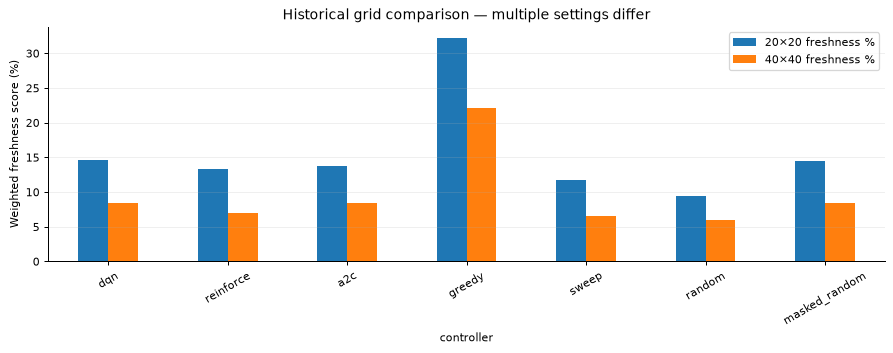

40×40 learner freshness minus masked random (percentage points):


policy
dqn          0.05889
reinforce   -1.47795
a2c          0.05531
Name: difference pp, dtype: float64

In [42]:
names20 = {'dqn':'masked dqn','reinforce':'masked reinforce','a2c':'masked a2c',
           'greedy':'greedy','sweep':'sweep','random':'random','masked_random':'masked random'}
historical_by_name = historical_summary.set_index('policy')
grid_rows = []
for policy in POLICIES:
    old = historical_by_name.loc[names20[policy]]
    new = main_means.loc[policy]
    grid_rows.append({'controller':policy,'20×20 freshness %':100*old['weighted_freshness_mean'],
                     '40×40 freshness %':100*new['weighted_freshness'],
                     '20×20 return':old['return_mean'],'40×40 return':new['return'],
                     '20×20 mean losses':old['total_losses_mean'],
                     '40×40 mean losses':new['total_losses']})
grid_comparison = pd.DataFrame(grid_rows).set_index('controller')
display(grid_comparison)
fig, ax = plt.subplots(figsize=(10,4))
grid_comparison[['20×20 freshness %','40×40 freshness %']].plot.bar(ax=ax)
ax.set_ylabel('Weighted freshness score (%)'); ax.set_title('Historical grid comparison — multiple settings differ')
ax.grid(axis='y',alpha=0.2); plt.xticks(rotation=30)
finish_plot(fig)
print('40×40 learner freshness minus masked random (percentage points):')
display(((main_means.loc[ALGORITHMS,'weighted_freshness']-
          main_means.loc['masked_random','weighted_freshness'])*100).rename('difference pp'))

**What improved:** feasibility rules made the recorded learned missions safe, study-integrity fixes aligned checkpoints and targets with their metadata, and the final study has stronger provenance and replay evidence. Improved traceability is not improved learned surveillance. The historical masked study and final main study both remain close to masked random in freshness.

**What remains weak:** the final learners did not reach useful surveillance quality relative to Greedy. Increasing the problem size did not establish a learning advantage. Supervised fitting on training states could be excellent while fresh-state action ranking and complete missions remained poor. Drone-centered inputs and broader data improved specific development diagnostics; loss-only ranking tuning then reduced mission quality. Those results explain why we stopped that direction, not why every possible architecture or objective would fail.

| Observation | Supported conclusion | Unresolved explanation |
| --- | --- | --- |
| Masked random has zero losses | Feasibility rules supply substantial safety | How much additional recharge coordination the learner acquires |
| DQN/A2C freshness near masked random | Little useful learned inspection gain in this budget | Representation, exploration, target noise and objective mismatch may all contribute |
| Strong training label fit, weak fresh rankings | Fitting the training corpus is insufficient | Which distribution shifts dominate autonomous missions |
| Better exact-reference missions than fitted scores | Approximation/ranking error matters in that diagnostic | Whether better supervised rankings would help long-horizon RL |
| More updates / slower exploration / alternate targets often fail | These tested interventions did not solve the task | A larger, separately designed study might have a different outcome |
| Training actors sampled, final actors used argmax | Training and evaluation policies differ | Main-study evidence does not isolate the effect of this mismatch |

The reward optimizes incremental inspection gain plus penalties, whereas headline freshness evaluates continuous recency. Their alignment is incomplete. The masks also shrink the decision set and embed battery knowledge. These are reasons to interpret results carefully, not retrospective proof of a unique cause.

Three training seeds provide limited precision. Shared scenario sequences and repeated final worlds require respecting dependence. Historical selected-validation scores are biased. A fixed 300-episode budget is evidence of performance at that budget, not proof of convergence. Synthetic state/full observability and uncalibrated fire/energy scales limit operational relevance.

Potential future studies could test an objective aligned with persistent freshness, a structured fleet decision representation, uncertainty/partial observations, a different charging layout or a matched scaling protocol. These are hypotheses, not completed improvements. Any new study needs its own declared settings, budget and untouched test scenarios. No further loss tuning, longer fitting or 60×60 run is required to document the present negative findings.

## 13. References

**Author: _(name)_**

1. Farama Foundation. [Create a Custom Environment](https://gymnasium.farama.org/introduction/create_custom_env/)
   and [environment API](https://gymnasium.farama.org/api/env/). Basis for reset/step/seeding
   and Gymnasium checks; no existing PettingZoo wildfire environment is claimed.
2. Mnih et al. (2015). [Human-level control through deep reinforcement learning](https://www.nature.com/articles/nature14236).
   Nature 518, 529–533, doi:10.1038/nature14236. DQN algorithm foundation.
3. Williams (1992). [Simple statistical gradient-following algorithms for connectionist reinforcement learning](https://doi.org/10.1007/BF00992696).
   Machine Learning 8, 229–256. REINFORCE foundation.
4. Mnih et al. (2016). [Asynchronous Methods for Deep Reinforcement Learning](https://proceedings.mlr.press/v48/mniha16.html).
   ICML/PMLR 48. n-step advantage actor–critic background. Our implementation is synchronous
   single-environment A2C, not the paper's asynchronous A3C architecture.
5. Viseras, Meissner and Marchal Gomez (2021). Wildfire front monitoring with multiple UAVs
   using deep Q-learning. IEEE Access. [doi:10.1109/ACCESS.2021.3055651](https://doi.org/10.1109/ACCESS.2021.3055651).
   Wildfire-fleet context from the approved proposal; not evidence that our synthetic dynamics
   are realistic or our fully observable setting will outperform planning.
6. Khoshdel, Luo and Afghah (2024). [PyroTrack](https://arxiv.org/abs/2403.11095).
   Belief-based deep reinforcement learning path planning for aerial wildfire monitoring in
   partially observable environments. Related work; this project's complete-state controller
   deliberately has a different observation assumption.
7. Julian and Kochenderfer (2019). [Distributed wildfire surveillance with autonomous aircraft using deep reinforcement learning](https://arxiv.org/abs/1810.04244).
   Journal of Guidance, Control, and Dynamics 42(8), 1768–1778. Related fleet/planning work,
   not a validation of this project's outcome or novelty.
8. van Hasselt, Guez and Silver (2016). [Deep Reinforcement Learning with Double Q-learning](https://arxiv.org/abs/1509.06461).
   AAAI. Basis for the optional Double DQN target: online action selection and target-network
   evaluation. Its reported overestimation reduction does not establish stability here.

The fire model is a deliberately simple stochastic cellular automaton. These references do
not calibrate its probabilities, physical cell size, wind or battery rates. Literature review
and measured/calibrated settings are still needed for practical deployment or publication.
9. Alshiekh, Bloem, Ehlers, Könighofer, Niekum and Topcu (2018). Safe reinforcement learning
   via shielding. AAAI. Basis for restricting the learned policy to feasible actions.